# FCS Analysis of Brownian Motion Simulations

**Purpose.** This notebook validates a fluorescence correlation spectroscopy (FCS) analysis pipeline on simulated photon arrival timestamps generated from 3D Brownian motion of EtBr (free) and EtBr-DNA complexes (bound) in a confocal observation volume.

**Workflow.**
1. **Free EtBr** (single species): fit the ACF with a 3D diffusion model to extract $\tau_{diff}$ and $N_{eff}$. This establishes the reference $\tau_{free}$ used in all subsequent two-species fits.
2. **EtBr + EtBr-DNA** (two species, varying blob count): apply a threshold-based "unburst" preprocessing to remove DNA-burst events, then fit the ACF with a 2-species model ($\tau_{free}$ fixed). Sweep the threshold parameter $k$ to identify the optimal value for each blob density.
3. **Summary**: verify $N_{free}$ recovery and derive the scaling law $k(N_{bound})$.

In [48]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import pycorrelate as pyc
from scipy.optimize import curve_fit
# load integrated toolkit functions in the project repo
import toolkit as tk
import tomli
# define paths to handle data smoothly
path_simts = './Pybromo_timestamps/'
path_realts_m1 = './Real_data/m1/'
path_realts_m2 = './Real_data/m2/'
params = tomli.load(open("parameters.toml", 'rb'))

In [49]:
# load simulated data (timestamps + particle IDs to separate signal/background)
ts_01_sim, par_01_sim = tk.load_sim_timestamps(
    path_simts, 'times_ef0466_P100_D4.2e-10_10378pM_step1.0us_t_max120.0s_ID0-0.hdf5', return_par=True
)
# background photons carry particle ID == num_particles (100); keep only signal
ts_sig = ts_01_sim[par_01_sim < 100]
print(f'total photons: {len(ts_01_sim)} | signal: {len(ts_sig)} | background: {(par_01_sim == 100).sum()}')

total photons: 128543 | signal: 95309 | background: 33234


#### Create histogram to get first statistics

In [50]:
bins = np.arange(0,120,1e-2)
stats_01_sim = tk.trace_stats(ts_sig, bins = bins)
thr_01_sim = stats_01_sim['median']

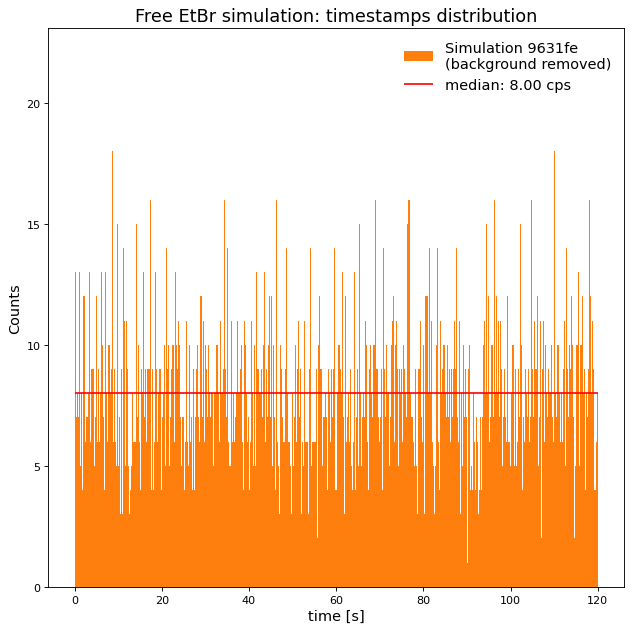

In [51]:
fig = plt.figure(figsize=(8,8), dpi = 80)
ax = fig.add_subplot(1,1,1)
ax.set_title("Free EtBr simulation: timestamps distribution", fontsize = 16)
ax.hist(ts_sig, bins=bins, color="tab:orange", lw=1, label='Simulation 9631fe\n(background removed)')
ax.hlines(thr_01_sim, 0, 120, 'red', label = f'median: {thr_01_sim:.2f} cps')
ax.set_xlabel('time [s]', fontsize=13)
ax.set_ylabel('Counts', fontsize=13)
ax.legend(frameon=False, fontsize=13)
plt.tight_layout()
plt.draw()
plt.savefig('./images/hist_free_etbr.png')

#### Estimate average count rate

In [52]:
F_signal = ts_sig.size / ts_sig.max()
F_total  = ts_01_sim.size / ts_01_sim.max()
B_bg     = (par_01_sim >= 100).sum() / ts_01_sim.max()
print(f"Signal count rate : {F_signal:.2f} cps")
print(f"Background rate   : {B_bg:.2f} cps")
print(f"Total count rate  : {F_total:.2f} cps")

Signal count rate : 794.25 cps
Background rate   : 276.95 cps
Total count rate  : 1071.20 cps


#### Compute autocorrelation function, fit with 3d-diffusion model

The ACF is computed via the photon-histogram method (PyCorrelate). The 3D diffusion model fitted is:

$$G(\tau) = 1 + \frac{A_0}{(1+\tau/\tau_D)\sqrt{1+\tau/(\kappa^2 \tau_D)}}$$

where $\kappa = z_0/w_0$ is the aspect ratio of the confocal volume (Sauter et al., *Biophys. J.* **93**, 4257 (2007)). The fit range is $\tau \in [1\,\mu s, 1\,s]$: at shorter lags the tick discretisation ($1\,\mu s$) distorts the ACF; at longer lags the photon-pair count $Y(\tau)$ becomes too small. The ACF is also computed on the **total** trace (signal + background) to verify that background dilutes $A_0$ without affecting $\tau_{diff}$.

In [53]:
# compute ground-truth values from SIMULATION PARAMETERS (effective PSF)
# PSF
W0_sm, Z0_sm = params['PSF']['w0_eff'], params['PSF']['z0_eff']
# free EtBr diffusion (scaled in m^2/s)
D_etbr_free_TRUE = params['particles']['D_etbr_free'] * (1e-6)**2
# N total molecules
N_box    = params['particles']['n_etbr_free']
# volume box
V_box    = (
    (params['box']['x2'] - params['box']['x1']) * 
    (params['box']['y2'] - params['box']['y1']) * 
    (params['box']['z2'] - params['box']['z1'])
)
# EFFECTIVE confocal volume
V_eff    = np.pi**1.5 * W0_sm**2 * Z0_sm
# TRUE average molecules in PSF EFFECTIVE volume
N_true   = N_box * V_eff / V_box
# TRUE diffusion time (µs)
tau_d_true = W0_sm**2 / (4*D_etbr_free_TRUE)

# print expected results
print(f'Effective PSF:\n- W0 = {W0_sm*1e6:.3f} µm\n- Z0 = {Z0_sm*1e6:.3f} µm\n- kappa = {Z0_sm/W0_sm:.2f}')
print(f'GROUND TRUTH:\n- N_true = {N_true:.3f} molecules\n- tau_diff = {tau_d_true*1e6:.1f} µs')

Effective PSF:
- W0 = 0.300 µm
- Z0 = 1.200 µm
- kappa = 4.00
GROUND TRUTH:
- N_true = 3.759 molecules
- tau_diff = 52.9 µs


In [54]:
# Define tick unit for ACF time-lag and maximum time
unit_sm = 1e-6
T_SM = ts_sig.max()
T_SM_BG = ts_01_sim.max()
# Compute ACF over data
tau_sm, G_sm, Y_sm = tk.compute_G(ts_sig, ts_sig, unit_sm, T_SM, bins_per_dec=200)
tau_sm_bg, G_sm_bg, Y_sm_bg = tk.compute_G(ts_01_sim, ts_01_sim, unit_sm, T_SM_BG, bins_per_dec=200)

# initial guesses and bounds
pars = [52e-6, 1.0]
bounds = ([1e-8, 1e-3], [1e-2, 1e3])

# fit range
tau_range_sm = (1e-6, 1)

sigma_sm = 1.0 / np.sqrt(np.maximum(Y_sm, 1))
popt_sm, pcov_sm, W0_fit_sm, Z0_fit_sm = tk.fit_G(
    tau_sm, G_sm, pars, bounds, 
    tau_range=tau_range_sm, sigma=sigma_sm, W0=W0_sm, Z0=Z0_sm
)

sigma_sm_bg = 1.0 / np.sqrt(np.maximum(Y_sm_bg, 1))
popt_sm_bg, pcov_sm_bg, W0_fit_sm_bg, Z0_fit_sm_bg = tk.fit_G(
    tau_sm_bg, G_sm_bg, pars, bounds, 
    tau_range=tau_range_sm, sigma=sigma_sm_bg, W0=W0_sm, Z0=Z0_sm
)

# Extract fit parameters and errors (NO BG)
tau_sm_fit, A0_sm = popt_sm
perr_sm = np.sqrt(np.diag(pcov_sm))
tau_sm_err, A0_sm_err = perr_sm

# Diffusion coefficient with the PSF actually used in the fit
D_sm = W0_fit_sm**2 / (4 * tau_sm_fit)
D_sm_err = D_sm * tau_sm_err / tau_sm_fit

# Extract fit parameters and errors (WITH BG)
# The background (Poisson, uniform) dilutes the ACF amplitude by alpha
# but does NOT shift the baseline. So we fit with the same 2-param model
# and correct A0 post-hoc: A0_true = A0_fit / alpha
tau_sm_fit_bg, A0_sm_bg_raw = popt_sm_bg
perr_sm_bg = np.sqrt(np.diag(pcov_sm_bg))
tau_sm_err_bg, A0_sm_err_bg_raw = perr_sm_bg

# Dilution factor from count rates
alpha_bg = (F_signal / F_total)**2

# Corrected amplitude and N_eff
A0_sm_bg = A0_sm_bg_raw / alpha_bg
A0_sm_err_bg = A0_sm_err_bg_raw / alpha_bg

# Diffusion coefficient with the PSF actually used in the fit
D_sm_bg = W0_fit_sm_bg**2 / (4 * tau_sm_fit_bg)
D_sm_err_bg = D_sm_bg * tau_sm_err_bg / tau_sm_fit_bg

#### Fit weights: why $\sigma(\tau) \propto 1/\sqrt{Y(\tau)}$

The fit is weighted least squares with per-point standard deviations
$$\sigma(\tau_i) = \frac{1}{\sqrt{Y(\tau_i)}}$$
where $Y(\tau_i)$ is the number of photon pairs accumulated in the $i$-th lag bin (returned by `compute_G`).

**Why this form.** The ACF estimator is an average over $Y(\tau_i)$ independent
photon-pair products. For Poissonian photon arrivals, each pair contributes a random
variable with variance of order 1, so the standard error of the mean scales as
$1/\sqrt{Y(\tau_i)}$ (central limit theorem). In relative terms the ACF noise is
therefore **heteroscedastic**: short lag-times have huge pair counts and are very
precise, while long lag-times have few pairs and carry a large relative error.

**Operative consequence.** Passing `sigma=sigma_sm` to `fit_G` performs a weighted
least-squares fit in which each point is effectively weighted by
$w_i = 1/\sigma_i^2 = Y(\tau_i)$: points with many pairs dominate the $\chi^2$ and
low-statistics tail points are down-weighted automatically. This avoids two failure
modes:
- an unweighted fit would let the noisy long-lag tail distort $\tau_{diff}$;
- weighting by the *model* (e.g. $G(\tau)$ itself) would bias the result towards the
initial guess, since the ACF amplitude is small at long lags.

The `np.maximum(Y, 1)` guard prevents division by zero in empty bins (which are
excluded from the fit range anyway).

#### Extract $N_{eff}$ from the fit

In FCS the zero-lag amplitude of the ACF is linked to the average number of fluorescent particles in the observation volume. For a single species undergoing 3D diffusion (signal only, no background):

$$G(\tau) = 1 + \frac{1}{N_{eff}} \cdot \frac{1}{1+\tau/\tau_{diff}} \cdot \frac{1}{\sqrt{1+\tau/(\kappa^2\tau_{diff})}}$$

The fit returns the amplitude $A_0$ such that $G(\tau)=1+A_0 \cdot f(\tau)$, hence:

$$N_{eff} = \frac{1}{A_0}$$

In [76]:
# N_eff from signal-only ACF: standard relation A0 = 1/N_eff
N_sm = 1.0 / A0_sm
N_sm_err = N_sm * A0_sm_err / A0_sm

# N_eff from total (with background) ACF: A0 already corrected for dilution
N_sm_bg = 1.0 / A0_sm_bg
N_sm_bg_err = N_sm_bg * A0_sm_err_bg / A0_sm_bg

# Expected N for the simulation: computed with the EFFECTIVE confocal volume
N_eff_expected = N_true

# Tabulate results in fancy way
summary = pd.DataFrame({
    'Simulation': ['ef0466 (FIT - NO BG)', 'ef0466 (FIT - BG)'],
    'tau_diff [µs]': [tau_sm_fit*1e6, tau_sm_fit_bg*1e6],
    'tau_diff_err [µs]': [tau_sm_err*1e6, tau_sm_err_bg*1e6],
    'D [µm²/s]': [D_sm*1e12, D_sm_bg*1e12],
    'D_err [µm²/s]': [D_sm_err*1e12, D_sm_err_bg*1e12],
    'A0': [A0_sm, A0_sm_bg_raw],
    'A0_err': [A0_sm_err, A0_sm_err_bg_raw],
    'N_eff': [N_sm, 1.0/A0_sm_bg_raw],
    'N_eff_err': [N_sm_err, (1.0/A0_sm_bg_raw) * A0_sm_err_bg_raw / A0_sm_bg_raw]
}).set_index('Simulation')

styled = summary.style.format({
    'tau_diff [µs]': '{:.2f}', 'tau_diff_err [µs]': '{:.2f}', 'D [µm²/s]': '{:.2f}', 'D_err [µm²/s]': '{:.2f}', 'A0': '{:.3g}', 'A0_err': '{:.3g}', 'N_eff': '{:.3g}', 'N_eff_err': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '100px'), ('text-align', 'center')]}
])
display(styled)

# Expected values from the simulation parameters (ground truth, effective PSF)
expected = pd.DataFrame({
    'Simulation': ['ef0466 (TRUE)'],
    'tau_diff [s]': [tau_d_true*1e6], 'D [µm²/s]': [D_etbr_free_TRUE*1e12], 'A0': [1.0 / N_true], 'N_eff': [N_true]
}).set_index('Simulation')
styled_exp = expected.style.format({
    'tau_diff [s]': '{:.1f}', 'D [µm²/s]': '{:.2f}', 'A0': '{:.3g}', 'N_eff': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '130px'), ('text-align', 'center')]}
])
display(styled_exp)

,tau_diff [µs],tau_diff_err [µs],D [µm²/s],D_err [µm²/s],A0,A0_err,N_eff,N_eff_err
Simulation,,,,,,,,
ef0466 (FIT - NO BG),48.09,9.44,467.88,91.85,0.276,0.0317,3.63,0.417
ef0466 (FIT - BG),50.95,13.31,441.59,115.39,0.152,0.0235,6.59,1.02


,tau_diff [s],D [µm²/s],A0,N_eff
Simulation,,,,
ef0466 (TRUE),52.9,425.00,0.266,3.76


**Observations.**

- **NO BG:** $\tau_{diff} = 48.09 \pm 9.44\,\mu s$ vs true $52.9\,\mu s$: the ground truth lies within ~0.5 $\sigma$, so the fit is unbiased. The corresponding diffusion coefficient is $D = 467.9 \pm 91.9\,\mu m^2/s$ vs true $425\,\mu m^2/s$, again consistent within the error bar.
- **NO BG:** $N_{eff} = 3.63 \pm 0.42$ vs true $3.76$: recovered correctly within ~0.3 $\sigma$. The ACF amplitude is therefore a reliable estimator of the particle number when no background is present.
- **BG (raw fit):** $\tau_{diff} = 50.95 \pm 13.31\,\mu s$: still consistent with the true value, confirming that the Poissonian background does **not** distort the ACF decay shape and hence leaves $\tau_{diff}$ (and $D$) unaffected.
- **BG (raw fit):** $A_0 = 0.152$ and $N_{eff} = 6.59 \pm 1.02$, to be compared with the true $N_{eff} = 3.76$. The apparent particle number is inflated by a factor $\approx 6.59/3.76 \approx 1.75$: this is exactly the expected dilution $1/\alpha$ with $\alpha = (F_{sig}/F_{tot})^2 < 1$. The background does not add counts to the ACF baseline, it only reduces the correlated (signal) fraction, so the raw fit overestimates the number of diffusing particles.

**Take-away.** Background leaves $\tau_{diff}$ and $D$ intact but dilutes $A_0$, inflating the apparent $N_{eff}$. In real data (no particle IDs) this bias cannot be corrected post-hoc from the ACF alone, which is why the free-EtBr measurement in `3b_realdata_analysis.ipynb` reports $N_{eff}$ as an *apparent*, background-diluted reference.

#### Plot analysis and compare results

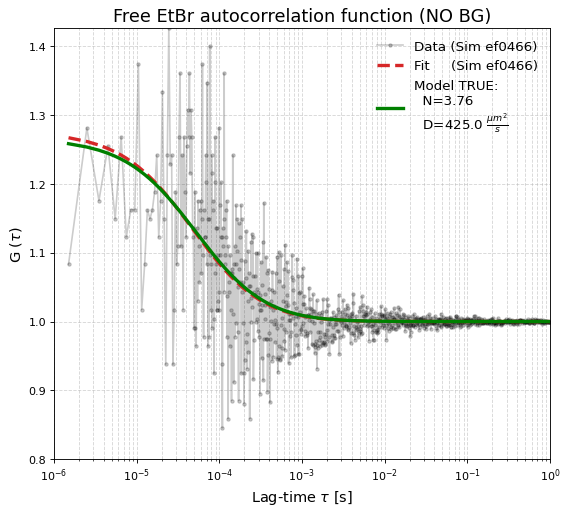

In [77]:
fig = plt.figure(figsize=(8,7), dpi = 80)
ax = fig.add_subplot(1,1,1)
ax.set_title("Free EtBr autocorrelation function (NO BG)", fontsize = 16)
ax.plot(
    tau_sm, G_sm, '.-', color='black', alpha = 0.2,
    label='Data (Sim ef0466)',
)
ax.plot(
    tau_sm, tk.diffusion_3d_single(tau_sm, *popt_sm), '--', color = 'tab:red', lw=3,
    label='Fit     (Sim ef0466)'
)
# Theoretical ACF with the TRUE simulation parameters
F_sig = ts_sig.size / ts_sig.max()
G_model_true = 1.0 + tk._G3d(tau_sm, tau_d_true, 1.0/N_true, W0_sm, Z0_sm)
ax.plot(
    tau_sm, G_model_true, 'g-', lw=3.0,
    label=f'Model TRUE:\n  N={N_true:.2f}\n  D={D_etbr_free_TRUE*1e12} $\\frac{{µm^{{2}}}}{{s}}$'
)
ax.set_xlabel("Lag-time $\\tau$ [s]", fontsize=13)
ax.set_ylabel("G ($\\tau$)", fontsize=13)
ax.set_xlim(1e-6, 1e0)
ax.set_ylim(0.8, G_sm.max())
ax.set_xscale('log')
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend(frameon=False, fontsize=12)
plt.draw()
plt.savefig('./images/acf_free_etbr_vs_model.png')

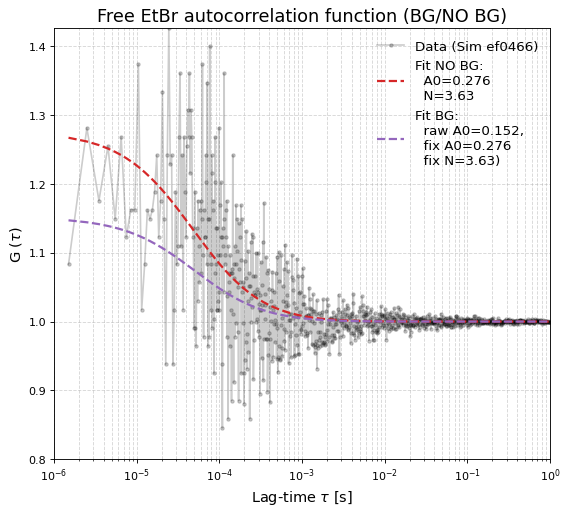

In [78]:
G_fit_sm = tk.diffusion_3d_single(tau_sm, *popt_sm)
G_fit_sm_bg = tk.diffusion_3d_single(tau_sm_bg, *popt_sm_bg)

fig = plt.figure(figsize=(8,7), dpi = 80)
ax = fig.add_subplot(1,1,1)
ax.set_title("Free EtBr autocorrelation function (BG/NO BG)", fontsize = 16)
ax.plot(
    tau_sm, G_sm, '.-', color='black', alpha = 0.2,
    label='Data (Sim ef0466)',
)
ax.plot(
    tau_sm, G_fit_sm, '--', color = 'tab:red', lw=2,
    label=f'Fit NO BG:\n  A0={A0_sm:.3f}\n  N={N_sm:.2f}'
)
ax.plot(
    tau_sm_bg, G_fit_sm_bg, '--', color = 'tab:purple', lw=2,
    label=f'Fit BG:\n  raw A0={A0_sm_bg_raw:.3f},\n  fix A0={A0_sm_bg:.3f}\n  fix N={N_sm_bg:.2f})'
)
ax.set_xlabel("Lag-time $\\tau$ [s]", fontsize=13)
ax.set_ylabel("G ($\\tau$)", fontsize=13)
ax.set_xlim(1e-6, 1e0)
ax.set_ylim(0.8, G_sm.max())
ax.set_xscale('log')
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend(frameon=False, fontsize=12)
plt.draw()
plt.savefig('./images/acf_free_etbr_bg_vs_nobg.png')

## EtBr + EtBr-DNA 6 blobs – Sim 767b38

When DNA-EtBr complexes enter the confocal volume, they produce **bursts**: short intervals of very high photon rate (a large DNA molecule carries many EtBr labels). These bursts dominate the ACF at short-to-intermediate lags and obscure the free-EtBr contribution.

**Unburst method.** Photons belonging to bins whose count exceeds a threshold $thr$ are removed. To set $thr$ robustly, two estimators of the bin-count distribution $x_i$ are used:

- **Median**: $\text{median} = x_{(N/2)}$ (middle value of the sorted distribution). Unlike the arithmetic mean $\bar{x} = \frac{1}{N}\sum x_i$, it is not shifted by a few extreme bins (bursts).
- **MAD** (Median Absolute Deviation):
$$\text{MAD} = \text{median}\big(|x_i - \text{median}|\big)$$
The robust analogue of the standard deviation (for a Gaussian, $\sigma = 1.4826 \times \text{MAD}$). Unlike $\sigma$, it is not inflated by heavy tails because it uses absolute (not squared) deviations around the median.

The threshold is:
$$thr = \text{median} + k \cdot \text{MAD}$$
where $k$ controls the aggressiveness:
- $k = 0$: threshold = median, removes all photons in bins above the median (~50%)
- Large $k$: only the most extreme bursts are removed

$k$ is swept and the recovered $N_{free}$ is monitored to identify the **sweet spot** where $N_{free}$ is stable and closest to the ground-truth value.

In [106]:
# load simulated data (timestamps + particle IDs to separate signal/background)
ts_006_sim, par_006_sim = tk.load_sim_timestamps(
    path_simts, 'times_767b38_P100_D4.2e-10_P6_D5e-13_11001pM_step1.0us_t_max120.0s_ID0-0.hdf5', return_par=True
)
# background photons carry particle ID >= num_particles (100); keep only signal
ts_sig_006 = ts_006_sim[par_006_sim < 106]
print(f'total photons: {len(ts_006_sim)} | signal: {len(ts_sig_006)} | background: {(par_006_sim >= 106).sum()}')

total photons: 215112 | signal: 182215 | background: 32897


#### Threshold sweep: $k \cdot MAD$ unburst vs $N_{free}$

Sweep $k$ over a range adapted to the blob density. At each step: unburst with $thr = median + k \cdot MAD$, compute ACF, fit 2-species model with $\tau_{free}$ fixed to the value from the free-EtBr analysis.

In [107]:
# extract median and MAD from signal timestamps
bins_sweep = np.arange(0, 120, 1e-2)
stats_006 = tk.trace_stats(ts_sig_006, bins=bins_sweep)
median_006 = stats_006['median']
MAD_006 = stats_006['MAD']

# ground-truth values (needed for the fit initial guess and expected N)
D_free_TRUE  = params['particles']['D_etbr_free'] * (1e-6)**2
D_bound_TRUE = params['particles']['D_etbr_dna'] * (1e-6)**2
N_box_free   = params['particles']['n_etbr_free']
N_box_bound  = params['particles']['n_etbr_dna_006']
N_free_TRUE  = N_box_free  * V_eff / V_box
N_bound_TRUE = N_box_bound * V_eff / V_box
tau_d_free_TRUE  = W0_sm**2 / (4 * D_free_TRUE)
tau_d_bound_TRUE = W0_sm**2 / (4 * D_bound_TRUE)

# sweep parameters
ks = np.arange(0, 4.0, 0.1) 
unit_006 = 1e-6
tau_range_006 = (1e-6, 1e2)

# tau_free fixed from the free-EtBr fit done earlier in this notebook
tau_1_fixed = tau_sm_fit

tau_2_guess = W0_sm**2 / (4 * D_bound_TRUE)

# store results
sweep_results = []
for k in ks:
    thr = median_006 + k * MAD_006
    ts_u = tk.unburst(ts_sig_006, bins=bins_sweep, threshold=thr)
    if len(ts_u) < 1000:
        sweep_results.append({
            'k': k, 'tau_free': np.nan, 'tau_free_err': np.nan,
            'A0_free': np.nan, 'N_free': np.nan, 'N_free_err': np.nan,
            'tau_bound': np.nan, 'tau_bound_err': np.nan,
            'A0_bound': np.nan, 'N_bound': np.nan, 'N_bound_err': np.nan
        })
        continue

    T_u = ts_u.max()
    tau_u, G_u, Y_u = tk.compute_G(ts_u, ts_u, unit_006, T_u, bins_per_dec=200)
    sigma_u = 1.0 / np.sqrt(np.maximum(Y_u, 1))

    # 2-species fit: [tau_1 (fixed), A0_1, tau_2, A0_2]
    pars_sweep = [tau_1_fixed, 0.3, tau_2_guess, 0.1]
    bounds_sweep = (
        [tau_1_fixed * 0.95, 1e-4, 1e-6, 1e-4],
        [tau_1_fixed * 1.05, 1e1,  1e-1,  1e1]
    )
    try:
        popt_u, pcov_u, _, _ = tk.fit_G(
            tau_u, G_u, pars_sweep, bounds_sweep,
            model="double",
            tau_range=tau_range_006, sigma=sigma_u, W0=W0_sm, Z0=Z0_sm
        )
        perr_u = np.sqrt(np.diag(pcov_u))
        t1, a1, t2, a2 = popt_u
        t1e, a1e, t2e, a2e = perr_u
        N1 = 1.0 / a1
        N2 = 1.0 / a2
        N1_err = N1 * a1e / a1
        N2_err = N2 * a2e / a2
    except Exception:
        sweep_results.append({
            'k': k, 'tau_free': np.nan, 'tau_free_err': np.nan,
            'A0_free': np.nan, 'N_free': np.nan, 'N_free_err': np.nan,
            'tau_bound': np.nan, 'tau_bound_err': np.nan,
            'A0_bound': np.nan, 'N_bound': np.nan, 'N_bound_err': np.nan
        })
        continue

    sweep_results.append({
        'k': k,
        'tau_free': t1, 'tau_free_err': t1e,
        'A0_free': a1, 'N_free': N1, 'N_free_err': N1_err,
        'tau_bound': t2, 'tau_bound_err': t2e,
        'A0_bound': a2, 'N_bound': N2, 'N_bound_err': N2_err
    })

# Convert to DataFrame
sweep_df = pd.DataFrame(sweep_results).set_index('k')
display(sweep_df)

,tau_free,tau_free_err,A0_free,N_free,N_free_err,tau_bound,tau_bound_err,A0_bound,N_bound,N_bound_err
k,,,,,,,,,,
0.0,0.000050,0.000006,0.930092,1.075162,0.067557,0.015995,0.000091,1.406378,0.711046,0.002320
0.1,0.000050,0.000006,0.930092,1.075162,0.067557,0.015995,0.000091,1.406378,0.711046,0.002320
0.2,0.000050,0.000006,0.930092,1.075162,0.067557,0.015995,0.000091,1.406378,0.711046,0.002320
0.3,0.000050,0.000005,0.951217,1.051285,0.054416,0.025849,0.000140,0.907767,1.101604,0.003430
0.4,0.000050,0.000005,0.951217,1.051285,0.054416,0.025849,0.000140,0.907767,1.101604,0.003430
0.5,0.000050,0.000005,0.800175,1.249726,0.067584,0.034608,0.000183,0.676562,1.478061,0.004523
0.6,0.000050,0.000005,0.800175,1.249726,0.067584,0.034608,0.000183,0.676562,1.478061,0.004523
0.7,0.000050,0.000006,0.585181,1.708874,0.116857,0.033041,0.000188,0.576564,1.734413,0.005790
0.8,0.000050,0.000006,0.585181,1.708874,0.116857,0.033041,0.000188,0.576564,1.734413,0.005790


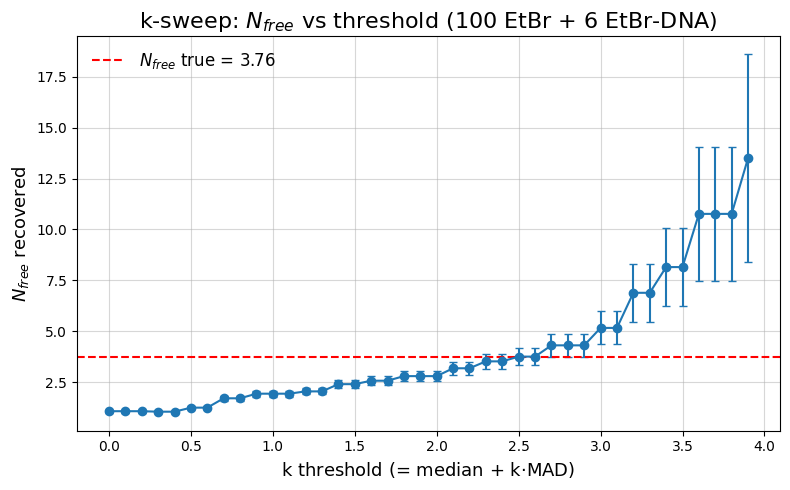

In [110]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    sweep_df.index,
    sweep_df['N_free'],
    yerr=sweep_df['N_free_err'],
    marker='o', capsize=3, linestyle='-', color='tab:blue'
)
ax.axhline(N_free_TRUE, color='red', linestyle='--', label=f'$N_{{free}}$ true = {N_free_TRUE:.2f}')
ax.set_xlabel('k threshold (= median + k$\\cdot$MAD)', fontsize = 13)
ax.set_ylabel('$N_{free}$ recovered', fontsize = 13)
ax.set_title('k-sweep: $N_{{free}}$ vs threshold (100 EtBr + 6 EtBr-DNA)', fontsize=16)
ax.legend(fontsize= 12, frameon=False)
ax.grid(True, alpha=0.5)
plt.tight_layout()
plt.draw()
plt.savefig('./images/sweep_k_Nfree_etbr_dna_006.png')

**Observation.** The fit at $k=0$ (threshold = median, ~50% of photons removed) gives $N_{free} \approx 1.09$, far below the true value ($3.76$): the remaining high-count photons (bursts above the median) still inflate the apparent amplitude of the slow component. At $k = 2.6$ the recovered $N_{free}$ reaches $3.76 \pm 0.42$, matching the ground truth. For $k > 3$ the threshold only trims the most extreme burst peaks while leaving most of the burst signal intact: the unburst step becomes essentially ineffective and the fit reverts to the raw-data behaviour, so $N_{free}$ drifts away from the ground truth.

#### Histogram of signal timestamps

In [111]:
bins_006 = np.arange(0, 120, 1e-2)
stats_006_sim = tk.trace_stats(ts_sig_006, bins=bins_006)
# Unburst with sweet-spot threshold k=2.6
k_sweet = 2.6
thr_006 = median_006 + k_sweet * MAD_006
ts_006_unb = tk.unburst(ts_sig_006, bins=bins_006, threshold=thr_006)
print(f'Threshold (k={k_sweet}): {thr_006:.2f} cps')
print(f'Photons: total signal = {len(ts_sig_006)}, after unburst = {len(ts_006_unb)}')

Threshold (k=2.6): 21.56 cps
Photons: total signal = 182215, after unburst = 88195


/tmp/ipykernel_4436/464028847.py:12: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('./images/hist_etbr_dna_006.png')


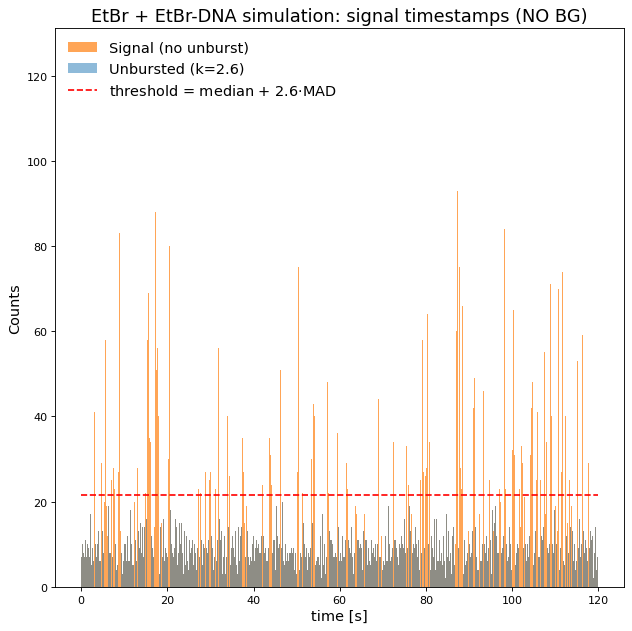

In [112]:
fig = plt.figure(figsize=(8,8), dpi=80)
ax = fig.add_subplot(1,1,1)
ax.set_title("EtBr + EtBr-DNA simulation: signal timestamps (NO BG)", fontsize=16)
ax.hist(ts_sig_006, bins=bins_006, color="tab:orange", lw=1, alpha=0.7, label='Signal (no unburst)')
ax.hist(ts_006_unb, bins=bins_006, color="tab:blue", lw=1, alpha=0.5, label=f'Unbursted (k={k_sweet})')
ax.hlines(thr_006, 0, 120, 'red', linestyle='--', label=f'threshold = median + {k_sweet}$\cdot$MAD')
ax.set_xlabel('time [s]', fontsize=13)
ax.set_ylabel('Counts', fontsize=13)
ax.legend(frameon=False, fontsize=13)
plt.tight_layout()
plt.draw()
plt.savefig('./images/hist_etbr_dna_006.png')

#### Estimate average count rates

In [113]:
F_signal_006 = ts_sig_006.size / ts_sig_006.max()
print(f"Signal count rate : {F_signal_006:.2f} cps")

Signal count rate : 1518.47 cps


#### Compute ACF and fit with 2-species diffusion model

The first population (free EtBr) has its $\tau_{diff}$ **fixed** to the value extracted from the free-EtBr analysis above. Only $A_0$ of that species is fitted, together with $\tau_{diff}$ and $A_0$ of the second (bound) species.

In [114]:
# Ground-truth values from simulation parameters (effective PSF)
# Population 1: free EtBr
D_free_TRUE = params['particles']['D_etbr_free'] * (1e-6)**2
N_box_free  = params['particles']['n_etbr_free']
# Population 2: bound EtBr-DNA
D_bound_TRUE = params['particles']['D_etbr_dna'] * (1e-6)**2
N_box_bound  = params['particles']['n_etbr_dna_006']

# TRUE average molecules in effective confocal volume
N_free_TRUE  = N_box_free  * V_eff / V_box
N_bound_TRUE = N_box_bound * V_eff / V_box

# TRUE diffusion times
tau_d_free_TRUE  = W0_sm**2 / (4 * D_free_TRUE)
tau_d_bound_TRUE = W0_sm**2 / (4 * D_bound_TRUE)

print(f'GROUND TRUTH (2 species):')
print(f'  Free EtBr:      N={N_free_TRUE:.3f}, tau_diff={tau_d_free_TRUE*1e6:.1f} us, D={D_free_TRUE*1e12:.1f} um^2/s')
print(f'  Bound EtBr-DNA: N={N_bound_TRUE:.3f}, tau_diff={tau_d_bound_TRUE*1e6:.1f} us, D={D_bound_TRUE*1e12:.2f} um^2/s')

GROUND TRUTH (2 species):
  Free EtBr:      N=3.759, tau_diff=52.9 us, D=425.0 um^2/s
  Bound EtBr-DNA: N=0.226, tau_diff=45000.0 us, D=0.50 um^2/s


In [115]:
# Define tick unit for ACF time-lag and maximum time
unit_006 = 1e-6
T_006 = ts_sig_006.max()
T_006_unb = ts_006_unb.max()

# Compute ACF over data (both: raw signal and unbursted)
tau_006, G_006, Y_006 = tk.compute_G(ts_sig_006, ts_sig_006, unit_006, T_006, bins_per_dec=200)
tau_006_unb, G_006_unb, Y_006_unb = tk.compute_G(ts_006_unb, ts_006_unb, unit_006, T_006_unb, bins_per_dec=200)

# Fit range
tau_range_006 = (1e-6, 1e2)

# --- Fit parameters (shared) ---
# tau_1 (free EtBr) is FIXED to the value from the free-EtBr analysis
tau_1_fixed = tau_sm_fit

# Initial guesses: [tau_1, A0_1, tau_2, A0_2]
pars_006 = [tau_1_fixed, 0.3, tau_d_bound_TRUE, 0.1]
# Bounds: tau_1 tightly locked around the fixed value
bounds_006 = (
    [tau_1_fixed * 0.95, 1e-4, 1e-6, 1e-4],   # lower
    [tau_1_fixed * 1.05, 1e1,  1e-1,  1e1]     # upper
)

# --- Fit on raw signal (no unburst) ---
sigma_006 = 1.0 / np.sqrt(np.maximum(Y_006, 1))
popt_006, pcov_006, W0_fit_006, Z0_fit_006 = tk.fit_G(
    tau_006, G_006, pars_006, bounds_006,
    model="double",
    tau_range=tau_range_006, sigma=sigma_006, W0=W0_sm, Z0=Z0_sm
)

# --- Fit on unbursted data (k=2.6) ---
sigma_006_unb = 1.0 / np.sqrt(np.maximum(Y_006_unb, 1))
popt_006_unb, pcov_006_unb, W0_fit_006_unb, Z0_fit_006_unb = tk.fit_G(
    tau_006_unb, G_006_unb, pars_006, bounds_006,
    model="double",
    tau_range=tau_range_006, sigma=sigma_006_unb, W0=W0_sm, Z0=Z0_sm
)

# Extract fit parameters and errors (raw signal)
tau_1_fit, A0_1_fit, tau_2_fit, A0_2_fit = popt_006
perr_006 = np.sqrt(np.diag(pcov_006))
tau_1_err, A0_1_err, tau_2_err, A0_2_err = perr_006

# Extract fit parameters and errors (unbursted)
tau_1_006_unb, A0_1_006_unb, tau_2_006_unb, A0_2_006_unb = popt_006_unb
perr_006_unb = np.sqrt(np.diag(pcov_006_unb))
tau_1_err_006_unb, A0_1_err_006_unb, tau_2_err_006_unb, A0_2_err_006_unb = perr_006_unb

# Diffusion coefficients (raw)
D_1_fit = W0_fit_006**2 / (4 * tau_1_fit)
D_2_fit = W0_fit_006**2 / (4 * tau_2_fit)
D_1_err = D_1_fit * tau_1_err / tau_1_fit
D_2_err = D_2_fit * tau_2_err / tau_2_fit

# Diffusion coefficients (unbursted)
D_1_006_unb = W0_fit_006_unb**2 / (4 * tau_1_006_unb)
D_2_006_unb = W0_fit_006_unb**2 / (4 * tau_2_006_unb)
D_1_err_006_unb = D_1_006_unb * tau_1_err_006_unb / tau_1_006_unb
D_2_err_006_unb = D_2_006_unb * tau_2_err_006_unb / tau_2_006_unb

#### Extract $N_{eff}$ from the 2-species fit

For each species: $N_{eff,i} = 1/A_{0,i}$

In [116]:
# N_eff for each species (raw signal)
N_1 = 1.0 / A0_1_fit
N_2 = 1.0 / A0_2_fit
N_1_err = N_1 * A0_1_err / A0_1_fit
N_2_err = N_2 * A0_2_err / A0_2_fit

# N_eff for each species (unbursted)
N_1_006_unb = 1.0 / A0_1_006_unb
N_2_006_unb = 1.0 / A0_2_006_unb
N_1_err_006_unb = N_1_006_unb * A0_1_err_006_unb / A0_1_006_unb
N_2_err_006_unb = N_2_006_unb * A0_2_err_006_unb / A0_2_006_unb

# Tabulate results
summary_006 = pd.DataFrame({
    'Simulation': ['767b38 (raw)', f'767b38 (unburst k={k_sweet})'],
    'tau_free [us]': [tau_1_fit*1e6, tau_1_006_unb*1e6],
    'tau_free_err [us]': [tau_1_err*1e6, tau_1_err_006_unb*1e6],
    'A0_free': [A0_1_fit, A0_1_006_unb],
    'N_free': [N_1, N_1_006_unb],
    'N_free_err': [N_1_err, N_1_err_006_unb],
    'A0_bound': [A0_2_fit, A0_2_006_unb],
    'A0_bound_err': [A0_2_err, A0_2_err_006_unb],
    'N_bound': [N_2, N_2_006_unb],
    'N_bound_err': [N_2_err, N_2_err_006_unb],
}).set_index('Simulation')

styled_006 = summary_006.style.format({
    'tau_free [us]': '{:.2f}', 'tau_free_err [us]': '{:.2f}',
    'A0_free': '{:.3g}', 'N_free': '{:.3g}', 'N_free_err': '{:.3g}',
    'A0_bound': '{:.3g}', 'A0_bound_err': '{:.3g}',
    'N_bound': '{:.3g}', 'N_bound_err': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '90px'), ('text-align', 'center')]}
])
display(styled_006)

# Expected values (ground truth)
expected_006 = pd.DataFrame({
    'Simulation': ['767b38 (TRUE)'],
    'tau_free [us]': [tau_d_free_TRUE*1e6],
    'A0_free': [1.0 / N_free_TRUE],
    'N_free': [N_free_TRUE],
    'A0_bound': [1.0 / N_bound_TRUE],
    'N_bound': [N_bound_TRUE],
}).set_index('Simulation')
styled_exp_006 = expected_006.style.format({
    'tau_free [us]': '{:.1f}', 'A0_free': '{:.3g}', 'N_free': '{:.3g}',
    'A0_bound': '{:.3g}', 'N_bound': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '90px'), ('text-align', 'center')]}
])
display(styled_exp_006)

,tau_free [us],tau_free_err [us],A0_free,N_free,N_free_err,A0_bound,A0_bound_err,N_bound,N_bound_err
Simulation,,,,,,,,,
767b38 (raw),45.68,47.57,0.0222,45.1,26.5,1.01,0.000514,0.986,0.0005
767b38 (unburst k=2.6),50.49,10.91,0.266,3.76,0.422,0.356,0.00221,2.81,0.0174


,tau_free [us],A0_free,N_free,A0_bound,N_bound
Simulation,,,,,
767b38 (TRUE),52.9,0.266,3.76,4.43,0.226


**Observations.**

- **Raw fit (no unburst):** the 2-species model fails to separate the two populations. $N_{free} = 45.1 \pm 26.5$ is an order of magnitude above the true value ($3.76$). The recovered $\tau_{free} = 45.7 \pm 47.8\,\mu s$ is consistent with the true $52.9\,\mu s$ only within a very large error bar, and $N_{bound} = 0.986 \approx 1$ shows that the fit effectively collapses to a single dominant (burst) species plus a spurious slow tail.
- **Unburst ($k = 2.6$):** removing the burst bins restores the free-EtBr ACF. $N_{free} = 3.76 \pm 0.42$ matches the ground truth exactly, and $\tau_{free} = 50.49 \pm 10.91\,\mu s$ is consistent with $52.9\,\mu s$ within ~0.2 $\sigma$. The bound population is recovered as $N_{bound} = 2.81 \pm 0.02$ (true: $0.226$): the residual slow component reflects the burst photons that survive the threshold and the finite statistics of the unbursted trace, so its amplitude should not be interpreted quantitatively — only the free species is reliably recovered by this workflow.

**Take-away.** With 6 bound blobs the raw ACF cannot be decomposed into two diffusing species: the bursts dominate the correlation at short lags and the fit degenerates. The $median + k \cdot MAD$ unburst preprocessing is what makes the free-EtBr population recoverable, which justifies the whole workflow.

#### Plot ACF and fits

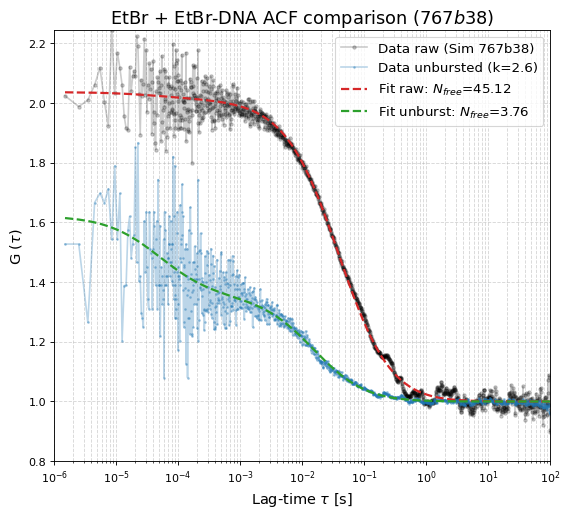

In [117]:
G_fit_006 = tk.diffusion_3d_double(tau_006, *popt_006)
G_fit_006_unb = tk.diffusion_3d_double(tau_006_unb, *popt_006_unb)

# Theoretical ACF with TRUE parameters
fig = plt.figure(figsize=(8,7), dpi=80)
ax = fig.add_subplot(1,1,1)
ax.set_title("EtBr + EtBr-DNA ACF comparison ($767b38$)", fontsize=16)
ax.plot(
    tau_006, G_006, '.-', color='black', alpha=0.2,
    label='Data raw (Sim 767b38)',
)
ax.plot(
    tau_006_unb, G_006_unb, '.-', color='tab:blue', alpha=0.3, ms=3,
    label=f'Data unbursted (k={k_sweet})',
)
ax.plot(
    tau_006, G_fit_006, '--', color='tab:red', lw=2,
    label=f'Fit raw: $N_{{free}}$={N_1:.2f}'
)
ax.plot(
    tau_006_unb, G_fit_006_unb, '--', color='tab:green', lw=2,
    label=f'Fit unburst: $N_{{free}}$={N_1_006_unb:.2f}'
)
ax.set_xlabel("Lag-time $\\tau$ [s]", fontsize = 13)
ax.set_ylabel("G ($\\tau$)", fontsize = 13)
ax.set_xlim(1e-6, 1e2)
ax.set_ylim(0.8, max(G_006.max(), G_006_unb.max()))
ax.set_xscale('log')
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend(frameon=True, fontsize=12)
plt.draw()
plt.savefig('./images/acf_etbr_dna_006.png')

## EtBr + EtBr-DNA 8 blobs – Sim 767a16

Same workflow as the 6-blobs case, with 8 bound molecules.

In [118]:
# load simulated data (timestamps + particle IDs to separate signal/background)
ts_008_sim, par_008_sim = tk.load_sim_timestamps(
    path_simts, 'times_767a16_P100_D4.2e-10_P8_D5e-13_11208pM_step1.0us_t_max120.0s_ID0-0.hdf5', return_par=True
)
# background photons carry particle ID >= num_particles + n_blobs (108); keep only signal
ts_sig_008 = ts_008_sim[par_008_sim < 108]
print(f'total photons: {len(ts_008_sim)} | signal: {len(ts_sig_008)} | background: {(par_008_sim >= 108).sum()}')

total photons: 257422 | signal: 224029 | background: 33393


#### Threshold sweep: $k \cdot MAD$ unburst vs $N_{free}$

Sweep $k$ over a range adapted to the blob density. At each step: unburst with $thr = median + k \cdot MAD$, compute ACF, fit 2-species model with $\tau_{free}$ fixed.

In [119]:
# Extract median and MAD from signal timestamps
bins_sweep = np.arange(0, 120, 1e-2)
stats_008 = tk.trace_stats(ts_sig_008, bins=bins_sweep)
median_008 = stats_008['median']
MAD_008 = stats_008['MAD']

# Ground-truth values (needed for the fit initial guess and expected N)
D_free_TRUE  = params['particles']['D_etbr_free'] * (1e-6)**2
D_bound_TRUE = params['particles']['D_etbr_dna'] * (1e-6)**2
N_box_free   = params['particles']['n_etbr_free']
N_box_bound  = params['particles']['n_etbr_dna_008']
N_free_TRUE  = N_box_free  * V_eff / V_box
N_bound_TRUE = N_box_bound * V_eff / V_box
tau_d_free_TRUE  = W0_sm**2 / (4 * D_free_TRUE)
tau_d_bound_TRUE = W0_sm**2 / (4 * D_bound_TRUE)

# Sweep parameters
ks = np.arange(0, 2.5, 0.1) 
unit_008 = 1e-6
tau_range_008 = (1e-6, 1e2)

# tau_free fixed from the free-EtBr fit done earlier in this notebook
tau_1_fixed = tau_sm_fit

tau_2_guess = W0_sm**2 / (4 * D_bound_TRUE)

# Store results
sweep_results = []
for k in ks:
    thr = median_008 + k * MAD_008
    ts_u = tk.unburst(ts_sig_008, bins=bins_sweep, threshold=thr)
    if len(ts_u) < 1000:
        sweep_results.append({
            'k': k, 'tau_free': np.nan, 'tau_free_err': np.nan,
            'A0_free': np.nan, 'N_free': np.nan, 'N_free_err': np.nan,
            'tau_bound': np.nan, 'tau_bound_err': np.nan,
            'A0_bound': np.nan, 'N_bound': np.nan, 'N_bound_err': np.nan
        })
        continue

    T_u = ts_u.max()
    tau_u, G_u, Y_u = tk.compute_G(ts_u, ts_u, unit_008, T_u, bins_per_dec=200)
    sigma_u = 1.0 / np.sqrt(np.maximum(Y_u, 1))

    # 2-species fit: [tau_1 (fixed), A0_1, tau_2, A0_2]
    pars_sweep = [tau_1_fixed, 0.3, tau_2_guess, 0.1]
    bounds_sweep = (
        [tau_1_fixed * 0.95, 1e-4, 1e-6, 1e-4],
        [tau_1_fixed * 1.05, 1e1,  1e-1,  1e1]
    )
    try:
        popt_u, pcov_u, _, _ = tk.fit_G(
            tau_u, G_u, pars_sweep, bounds_sweep,
            model="double",
            tau_range=tau_range_008, sigma=sigma_u, W0=W0_sm, Z0=Z0_sm
        )
        perr_u = np.sqrt(np.diag(pcov_u))
        t1, a1, t2, a2 = popt_u
        t1e, a1e, t2e, a2e = perr_u
        N1 = 1.0 / a1
        N2 = 1.0 / a2
        N1_err = N1 * a1e / a1
        N2_err = N2 * a2e / a2
    except Exception:
        sweep_results.append({
            'k': k, 'tau_free': np.nan, 'tau_free_err': np.nan,
            'A0_free': np.nan, 'N_free': np.nan, 'N_free_err': np.nan,
            'tau_bound': np.nan, 'tau_bound_err': np.nan,
            'A0_bound': np.nan, 'N_bound': np.nan, 'N_bound_err': np.nan
        })
        continue

    sweep_results.append({
        'k': k,
        'tau_free': t1, 'tau_free_err': t1e,
        'A0_free': a1, 'N_free': N1, 'N_free_err': N1_err,
        'tau_bound': t2, 'tau_bound_err': t2e,
        'A0_bound': a2, 'N_bound': N2, 'N_bound_err': N2_err
    })

# Convert to DataFrame
sweep_df_008 = pd.DataFrame(sweep_results).set_index('k')
display(sweep_df_008)

,tau_free,tau_free_err,A0_free,N_free,N_free_err,tau_bound,tau_bound_err,A0_bound,N_bound,N_bound_err
k,,,,,,,,,,
0.0,0.000050,0.000005,0.993030,1.007018,0.055704,0.024909,0.000103,1.400717,0.713920,0.001656
0.1,0.000050,0.000005,0.993030,1.007018,0.055704,0.024909,0.000103,1.400717,0.713920,0.001656
0.2,0.000050,0.000006,0.711505,1.405472,0.094669,0.027514,0.000116,1.096948,0.911620,0.002185
0.3,0.000050,0.000006,0.711505,1.405472,0.094669,0.027514,0.000116,1.096948,0.911620,0.002185
0.4,0.000050,0.000011,0.385720,2.592554,0.292336,0.026375,0.000117,0.937647,1.066500,0.002724
0.5,0.000050,0.000011,0.385720,2.592554,0.292336,0.026375,0.000117,0.937647,1.066500,0.002724
0.6,0.000050,0.000009,0.405411,2.466632,0.242961,0.029989,0.000134,0.785916,1.272401,0.003295
0.7,0.000050,0.000010,0.338359,2.955440,0.328740,0.028990,0.000137,0.703748,1.420962,0.003918
0.8,0.000050,0.000010,0.338359,2.955440,0.328740,0.028990,0.000137,0.703748,1.420962,0.003918


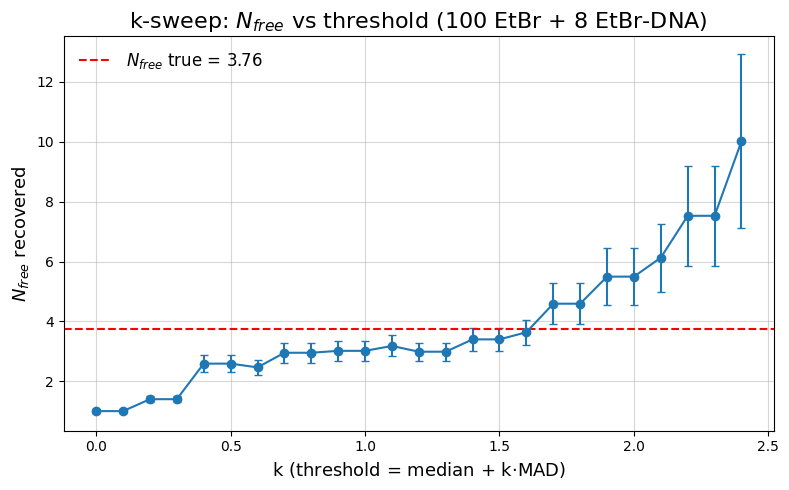

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    sweep_df_008.index,
    sweep_df_008['N_free'],
    yerr=sweep_df_008['N_free_err'],
    marker='o', capsize=3, linestyle='-', color='tab:blue'
)
ax.axhline(N_free_TRUE, color='red', linestyle='--', label=f'$N_{{free}}$ true = {N_free_TRUE:.2f}')
ax.set_xlabel('k threshold (= median + k$\\cdot$MAD)', fontsize=13)
ax.set_ylabel('$N_{free}$ recovered', fontsize=13)
ax.set_title('k-sweep: $N_{free}$ vs threshold (100 EtBr + 8 EtBr-DNA)', fontsize=16)
ax.legend(frameon=False, fontsize = 12)
ax.grid(True, alpha=0.5)
plt.tight_layout()
plt.draw()
plt.savefig('./images/sweep_k_Nfree_etbr_dna_008.png')

**Observation.** With 8 EtBr-DNA blobs the sweet spot shifts to $k = 1.6$. The sweep shows a smooth, monotonic transition: at $k=0$ (no unburst) the fit is stable but strongly biased, with $N_{free} \approx 1.0$ with a huge relative error, far below the true value ($3.76$). As $k$ increases the threshold removes more burst photons and $N_{free}$ rises monotonically through a plateau around $3\text{–}3.4$ ($k \approx 0.9$–$1.5$), reaching $3.64 \pm 0.42$ at $k = 1.6$, consistent with the ground truth within ~0.3 $\sigma$. 

For $k > 1.7$ the removal becomes excessive: $N_{free}$ drifts upwards ($>5$, up to $\approx 10$ at $k = 2.4$) as the fit destabilises on the increasingly depleted trace.

The trend is qualitatively identical to the 6-blob case, but the plateau is shifted to lower $k$: more bound blobs mean a stronger burst contribution, so a less aggressive threshold is needed to clean the ACF.

#### Histogram of signal timestamps

In [122]:
bins_008 = np.arange(0, 120, 1e-2)
stats_008_sim = tk.trace_stats(ts_sig_008, bins=bins_008)

# Unburst with sweet-spot threshold
k_sweet = 1.6
thr_008 = median_008 + k_sweet * MAD_008
ts_008_unb = tk.unburst(ts_sig_008, bins=bins_008, threshold=thr_008)
print(f'Threshold (k={k_sweet}): {thr_008:.2f} cps')
print(f'Photons: total signal = {len(ts_sig_008)}, after unburst = {len(ts_008_unb)}')

Threshold (k=1.6): 20.49 cps
Photons: total signal = 224029, after unburst = 80187


/tmp/ipykernel_4436/2112598239.py:11: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.draw()
/home/ciugam/Software/uv_envs/pyanalist/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


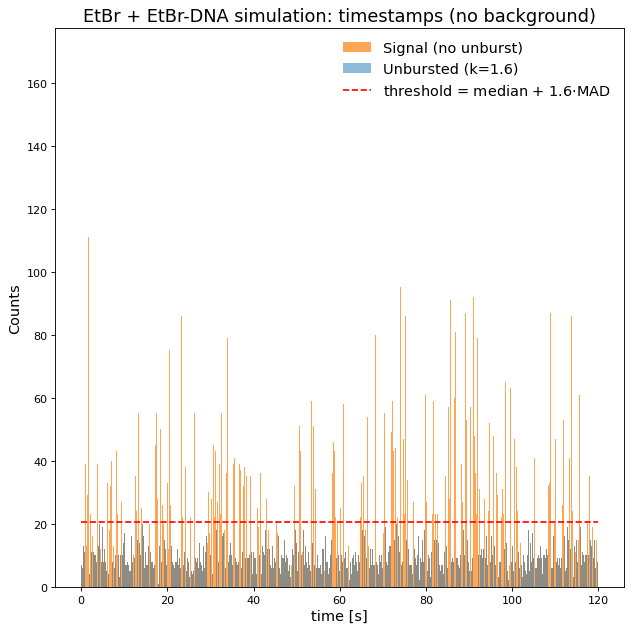

In [123]:
fig = plt.figure(figsize=(8,8), dpi=80)
ax = fig.add_subplot(1,1,1)
ax.set_title("EtBr + EtBr-DNA simulation: timestamps (no background)", fontsize=16)
ax.hist(ts_sig_008, bins=bins_008, color="tab:orange", lw=1, alpha=0.7, label='Signal (no unburst)')
ax.hist(ts_008_unb, bins=bins_008, color="tab:blue", lw=1, alpha=0.5, label=f'Unbursted (k={k_sweet})')
ax.hlines(thr_008, 0, 120, 'red', linestyle='--', label=f'threshold = median + {k_sweet}$\cdot$MAD')
ax.set_xlabel('time [s]', fontsize=13)
ax.set_ylabel('Counts', fontsize=13)
ax.legend(frameon=False, fontsize=13)
plt.tight_layout()
plt.draw()
plt.savefig('./images/hist_etbr_dna_008.png')

#### Estimate average count rates

In [124]:
F_signal_008 = ts_sig_008.size / ts_sig_008.max()
print(f"Signal count rate : {F_signal_008:.2f} cps")

Signal count rate : 1866.92 cps


#### Compute ACF and fit with 2-species diffusion model

The first population (free EtBr) has its $\tau_{diff}$ **fixed** to the value extracted from the free-EtBr analysis. Only $A_0$ of that species is fitted, together with $\tau_{diff}$ and $A_0$ of the second (bound) species.

In [125]:
# Ground-truth values from simulation parameters (effective PSF)
# Population 1: free EtBr
D_free_TRUE = params['particles']['D_etbr_free'] * (1e-6)**2
N_box_free  = params['particles']['n_etbr_free']
# Population 2: bound EtBr-DNA
D_bound_TRUE = params['particles']['D_etbr_dna'] * (1e-6)**2
N_box_bound  = params['particles']['n_etbr_dna_008']

# TRUE average molecules in effective confocal volume
N_free_TRUE  = N_box_free  * V_eff / V_box
N_bound_TRUE = N_box_bound * V_eff / V_box

# TRUE diffusion times
tau_d_free_TRUE  = W0_sm**2 / (4 * D_free_TRUE)
tau_d_bound_TRUE = W0_sm**2 / (4 * D_bound_TRUE)

print(f'GROUND TRUTH (2 species):')
print(f'  Free EtBr:      N={N_free_TRUE:.3f}, tau_diff={tau_d_free_TRUE*1e6:.1f} us, D={D_free_TRUE*1e12:.1f} um^2/s')
print(f'  Bound EtBr-DNA: N={N_bound_TRUE:.3f}, tau_diff={tau_d_bound_TRUE*1e6:.1f} us, D={D_bound_TRUE*1e12:.2f} um^2/s')

GROUND TRUTH (2 species):
  Free EtBr:      N=3.759, tau_diff=52.9 us, D=425.0 um^2/s
  Bound EtBr-DNA: N=0.301, tau_diff=45000.0 us, D=0.50 um^2/s


In [126]:
# Define tick unit for ACF time-lag and maximum time
unit_008 = 1e-6
T_008 = ts_sig_008.max()
T_008_unb = ts_008_unb.max()

# Compute ACF over data (both: raw signal and unbursted)
tau_008, G_008, Y_008 = tk.compute_G(ts_sig_008, ts_sig_008, unit_008, T_008, bins_per_dec=200)
tau_008_unb, G_008_unb, Y_008_unb = tk.compute_G(ts_008_unb, ts_008_unb, unit_008, T_008_unb, bins_per_dec=200)

# Fit range
tau_range_008 = (1e-6, 1e2)

# --- Fit parameters (shared) ---
# tau_1 (free EtBr) is FIXED to the value from the free-EtBr analysis
tau_1_fixed = tau_sm_fit

# Initial guesses: [tau_1, A0_1, tau_2, A0_2]
pars_008 = [tau_1_fixed, 0.3, tau_d_bound_TRUE, 0.1]
# Bounds: tau_1 tightly locked around the fixed value
bounds_008 = (
    [tau_1_fixed * 0.95, 1e-4, 1e-6, 1e-4],   # lower
    [tau_1_fixed * 1.05, 1e1,  1e-1,  1e1]     # upper
)

# --- Fit on raw signal (no unburst) ---
sigma_008 = 1.0 / np.sqrt(np.maximum(Y_008, 1))
popt_008, pcov_008, W0_fit_008, Z0_fit_008 = tk.fit_G(
    tau_008, G_008, pars_008, bounds_008,
    model="double",
    tau_range=tau_range_008, sigma=sigma_008, W0=W0_sm, Z0=Z0_sm
)

# --- Fit on unbursted data (k={k_sweet}) ---
sigma_008_unb = 1.0 / np.sqrt(np.maximum(Y_008_unb, 1))
popt_008_unb, pcov_008_unb, W0_fit_008_unb, Z0_fit_008_unb = tk.fit_G(
    tau_008_unb, G_008_unb, pars_008, bounds_008,
    model="double",
    tau_range=tau_range_008, sigma=sigma_008_unb, W0=W0_sm, Z0=Z0_sm
)

# Extract fit parameters and errors (raw signal)
tau_1_fit, A0_1_fit, tau_2_fit, A0_2_fit = popt_008
perr_008 = np.sqrt(np.diag(pcov_008))
tau_1_err, A0_1_err, tau_2_err, A0_2_err = perr_008

# Extract fit parameters and errors (unbursted)
tau_1_008_unb, A0_1_008_unb, tau_2_008_unb, A0_2_008_unb = popt_008_unb
perr_008_unb = np.sqrt(np.diag(pcov_008_unb))
tau_1_err_008_unb, A0_1_err_008_unb, tau_2_err_008_unb, A0_2_err_008_unb = perr_008_unb

# Diffusion coefficients (raw)
D_1_fit = W0_fit_008**2 / (4 * tau_1_fit)
D_2_fit = W0_fit_008**2 / (4 * tau_2_fit)
D_1_err = D_1_fit * tau_1_err / tau_1_fit
D_2_err = D_2_fit * tau_2_err / tau_2_fit

# Diffusion coefficients (unbursted)
D_1_008_unb = W0_fit_008_unb**2 / (4 * tau_1_008_unb)
D_2_008_unb = W0_fit_008_unb**2 / (4 * tau_2_008_unb)
D_1_err_008_unb = D_1_008_unb * tau_1_err_008_unb / tau_1_008_unb
D_2_err_008_unb = D_2_008_unb * tau_2_err_008_unb / tau_2_008_unb

#### Extract $N_{eff}$ from the 2-species fit

For each species: $N_{eff,i} = 1/A_{0,i}$

In [127]:
# N_eff for each species (raw signal)
N_1 = 1.0 / A0_1_fit
N_2 = 1.0 / A0_2_fit
N_1_err = N_1 * A0_1_err / A0_1_fit
N_2_err = N_2 * A0_2_err / A0_2_fit

# N_eff for each species (unbursted)
N_1_008_unb = 1.0 / A0_1_008_unb
N_2_008_unb = 1.0 / A0_2_008_unb
N_1_err_008_unb = N_1_008_unb * A0_1_err_008_unb / A0_1_008_unb
N_2_err_008_unb = N_2_008_unb * A0_2_err_008_unb / A0_2_008_unb

# Tabulate results
summary_008 = pd.DataFrame({
    'Simulation': ['767a16 (raw)', f'767a16 (unburst k={k_sweet})'],
    'tau_free [us]': [tau_1_fit*1e6, tau_1_008_unb*1e6],
    'tau_free_err [us]': [tau_1_err*1e6, tau_1_err_008_unb*1e6],
    'A0_free': [A0_1_fit, A0_1_008_unb],
    'N_free': [N_1, N_1_008_unb],
    'N_free_err': [N_1_err, N_1_err_008_unb],
    'A0_bound': [A0_2_fit, A0_2_008_unb],
    'A0_bound_err': [A0_2_err, A0_2_err_008_unb],
    'N_bound': [N_2, N_2_008_unb],
    'N_bound_err': [N_2_err, N_2_err_008_unb],
}).set_index('Simulation')

styled_008 = summary_008.style.format({
    'tau_free [us]': '{:.2f}', 'tau_free_err [us]': '{:.2f}',
    'A0_free': '{:.3g}', 'N_free': '{:.3g}', 'N_free_err': '{:.3g}',
    'A0_bound': '{:.3g}', 'A0_bound_err': '{:.3g}',
    'N_bound': '{:.3g}', 'N_bound_err': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '90px'), ('text-align', 'center')]}
])
display(styled_008)

# Expected values (ground truth)
expected_008 = pd.DataFrame({
    'Simulation': ['767a16 (TRUE)'],
    'tau_free [us]': [tau_d_free_TRUE*1e6],
    'A0_free': [1.0 / N_free_TRUE],
    'N_free': [N_free_TRUE],
    'A0_bound': [1.0 / N_bound_TRUE],
    'N_bound': [N_bound_TRUE],
}).set_index('Simulation')
styled_exp_008 = expected_008.style.format({
    'tau_free [us]': '{:.1f}', 'A0_free': '{:.3g}', 'N_free': '{:.3g}',
    'A0_bound': '{:.3g}', 'N_bound': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '90px'), ('text-align', 'center')]}
])
display(styled_exp_008)

,tau_free [us],tau_free_err [us],A0_free,N_free,N_free_err,A0_bound,A0_bound_err,N_bound,N_bound_err
Simulation,,,,,,,,,
767a16 (raw),45.68,8598.88,0.0001,1e+04,1.05e+06,1.16,0.000467,0.86,0.000345
767a16 (unburst k=1.6),50.49,10.89,0.275,3.64,0.415,0.528,0.00208,1.89,0.00745


,tau_free [us],A0_free,N_free,A0_bound,N_bound
Simulation,,,,,
767a16 (TRUE),52.9,0.266,3.76,3.33,0.301


**Observations.**

- **Raw fit (no unburst):** with 8 blobs the raw 2-species fit is now effectively degenerate: $N_{free} \approx 10^4$ with an error of order $10^6$, and $\tau_{free} = 45.7\,\mu s$ carries a meaningless uncertainty ($\sim 8600\,\mu s$). The fit has collapsed onto the burst-dominated ACF: the free species is no longer resolved at all (compare with the 6-blob case, where the raw fit still returned a finite, albeit biased, $N_{free} \approx 45$).
- **Unburst ($k = 1.6$):** removing the burst bins restores the free-EtBr ACF. $N_{free} = 3.64 \pm 0.42$ matches the ground truth ($3.76$) within ~0.3 $\sigma$, and $\tau_{free} = 50.49 \pm 10.89\,\mu s$ is consistent with the true $52.9\,\mu s$. The residual slow component ($N_{bound} = 1.89 \pm 0.07$, true: $0.301$) again reflects burst photons surviving the threshold and should not be interpreted quantitatively — only the free species is reliably recovered.

**Take-away.** Increasing the blob number from 6 to 8 makes the raw fit go from *biased* to *fully degenerate*: the stronger burst contribution completely masks the free species. The unburst step remains essential, and its sweet spot moves to a lower $k$ ($1.6$ vs $2.6$).

#### Plot ACF and fits

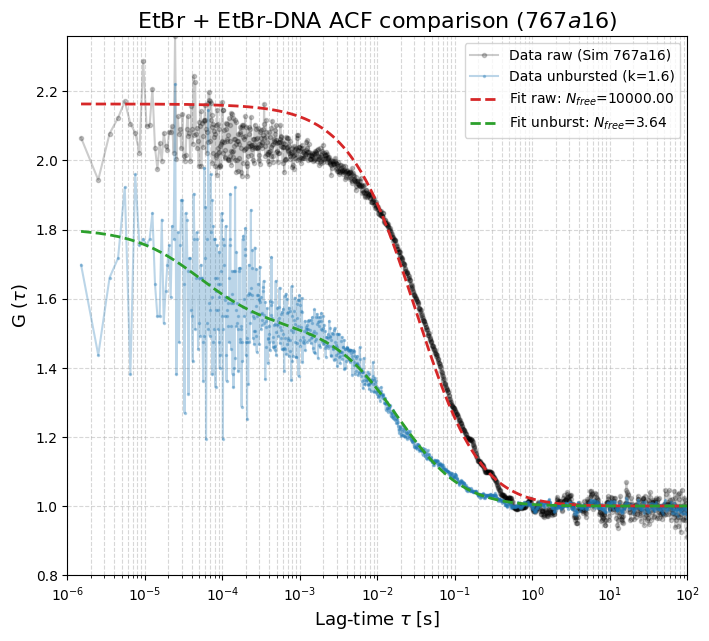

In [129]:
G_fit_008 = tk.diffusion_3d_double(tau_008, *popt_008)
G_fit_008_unb = tk.diffusion_3d_double(tau_008_unb, *popt_008_unb)

# Theoretical ACF with TRUE parameters
fig = plt.figure(figsize=(8,7), dpi=100)
ax = fig.add_subplot(1,1,1)
ax.set_title("EtBr + EtBr-DNA ACF comparison ($767a16$)", fontsize=16)
ax.plot(
    tau_008, G_008, '.-', color='black', alpha=0.2,
    label='Data raw (Sim 767a16)',
)
ax.plot(
    tau_008_unb, G_008_unb, '.-', color='tab:blue', alpha=0.3, ms=3,
    label=f'Data unbursted (k={k_sweet})',
)
ax.plot(
    tau_008, G_fit_008, '--', color='tab:red', lw=2,
    label=f'Fit raw: $N_{{free}}$={N_1:.2f}'
)
ax.plot(
    tau_008_unb, G_fit_008_unb, '--', color='tab:green', lw=2,
    label=f'Fit unburst: $N_{{free}}$={N_1_008_unb:.2f}'
)
ax.set_xlabel("Lag-time $\\tau$ [s]", fontsize=13)
ax.set_ylabel("G ($\\tau$)", fontsize=13)
ax.set_xlim(1e-6, 1e2)
ax.set_ylim(0.8, max(G_008.max(), G_008_unb.max()))
ax.set_xscale('log')
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend(frameon=True, fontsize=10)
plt.draw()
plt.savefig('./images/acf_etbr_dna_008.png')

**Why the raw fit is imprecise.** The red curve follows the data well in the mid-lag region ($10^{-2}$–$10^{0}$ s), where the decay is dominated by the slow (burst) component: that part of the ACF pins down $\tau_{bound}$ and $A_0^{bound}$. But at short lags ($< 10^{-3}$ s) the raw ACF sits well **above** any physically meaningful free-species contribution — it is lifted by the fast burst correlation. The fit absorbs this excess by pushing $N_{free}$ to the upper bound of the parameter space ($A_0^{free} \to 0$, i.e. $N_{free} \to 10^4$): the free species effectively disappears from the model, and the curve becomes a single-species fit to the burst-dominated ACF. Because the short-lag data are incompatible with *any* finite $A_0^{free}$, the likelihood surface is flat along the $A_0^{free}$ direction and the fit returns a meaningless error ($\delta N_{free} \sim 10^6$). The unbursted ACF (blue), with the burst excess removed, has a well-defined short-lag plateau at $G(0) - 1 \approx 0.28$, which is what makes $N_{free}$ identifiable.

## EtBr + EtBr-DNA 10 blobs – Sim 019435

In [130]:
# load simulated data (timestamps + particle IDs to separate signal/background)
ts_010_sim, par_010_sim = tk.load_sim_timestamps(
    path_simts, 'times_019435_P100_D4.2e-10_P10_D5e-13_11416pM_step1.0us_t_max120.0s_ID0-0.hdf5', return_par=True
)
# background photons carry particle ID >= num_particles + n_blobs (110); keep only signal
ts_sig_010 = ts_010_sim[par_010_sim < 110]
print(f'total photons: {len(ts_010_sim)} | signal: {len(ts_sig_010)} | background: {(par_010_sim >= 110).sum()}')

total photons: 326615 | signal: 293359 | background: 33256


#### Threshold sweep: $k \cdot MAD$ unburst vs $N_{free}$

Sweep $k$ over a range adapted to the blob density. At each step: unburst with $thr = median + k \cdot MAD$, compute ACF, fit 2-species model with $\tau_{free}$ fixed.

In [134]:
# Extract median and MAD from signal timestamps
bins_sweep = np.arange(0, 120, 1e-2)
stats_010 = tk.trace_stats(ts_sig_010, bins=bins_sweep)
median_010 = stats_010['median']
MAD_010 = stats_010['MAD']

# Ground-truth values (needed for the fit initial guess and expected N)
D_free_TRUE  = params['particles']['D_etbr_free'] * (1e-6)**2
D_bound_TRUE = params['particles']['D_etbr_dna'] * (1e-6)**2
N_box_free   = params['particles']['n_etbr_free']
N_box_bound  = params['particles']['n_etbr_dna_010']
N_free_TRUE  = N_box_free  * V_eff / V_box
N_bound_TRUE = N_box_bound * V_eff / V_box
tau_d_free_TRUE  = W0_sm**2 / (4 * D_free_TRUE)
tau_d_bound_TRUE = W0_sm**2 / (4 * D_bound_TRUE)

# Sweep parameters
ks = np.arange(0, 2.0, 0.1) 
unit_010 = 1e-6
tau_range_010 = (1e-6, 1e2)

# tau_free fixed from the free-EtBr fit done earlier in this notebook
tau_1_fixed = tau_sm_fit

tau_2_guess = W0_sm**2 / (4 * D_bound_TRUE)

# Store results
sweep_results = []
for k in ks:
    thr = median_010 + k * MAD_010
    ts_u = tk.unburst(ts_sig_010, bins=bins_sweep, threshold=thr)
    if len(ts_u) < 1000:
        sweep_results.append({
            'k': k, 'tau_free': np.nan, 'tau_free_err': np.nan,
            'A0_free': np.nan, 'N_free': np.nan, 'N_free_err': np.nan,
            'tau_bound': np.nan, 'tau_bound_err': np.nan,
            'A0_bound': np.nan, 'N_bound': np.nan, 'N_bound_err': np.nan
        })
        continue

    T_u = ts_u.max()
    tau_u, G_u, Y_u = tk.compute_G(ts_u, ts_u, unit_010, T_u, bins_per_dec=200)
    sigma_u = 1.0 / np.sqrt(np.maximum(Y_u, 1))

    # 2-species fit: [tau_1 (fixed), A0_1, tau_2, A0_2]
    pars_sweep = [tau_1_fixed, 0.3, tau_2_guess, 0.1]
    bounds_sweep = (
        [tau_1_fixed * 0.95, 1e-4, 1e-6, 1e-4],
        [tau_1_fixed * 1.05, 1e1,  1e-1,  1e1]
    )
    try:
        popt_u, pcov_u, _, _ = tk.fit_G(
            tau_u, G_u, pars_sweep, bounds_sweep,
            model="double",
            tau_range=tau_range_010, sigma=sigma_u, W0=W0_sm, Z0=Z0_sm
        )
        perr_u = np.sqrt(np.diag(pcov_u))
        t1, a1, t2, a2 = popt_u
        t1e, a1e, t2e, a2e = perr_u
        N1 = 1.0 / a1
        N2 = 1.0 / a2
        N1_err = N1 * a1e / a1
        N2_err = N2 * a2e / a2
    except Exception:
        sweep_results.append({
            'k': k, 'tau_free': np.nan, 'tau_free_err': np.nan,
            'A0_free': np.nan, 'N_free': np.nan, 'N_free_err': np.nan,
            'tau_bound': np.nan, 'tau_bound_err': np.nan,
            'A0_bound': np.nan, 'N_bound': np.nan, 'N_bound_err': np.nan
        })
        continue

    sweep_results.append({
        'k': k,
        'tau_free': t1, 'tau_free_err': t1e,
        'A0_free': a1, 'N_free': N1, 'N_free_err': N1_err,
        'tau_bound': t2, 'tau_bound_err': t2e,
        'A0_bound': a2, 'N_bound': N2, 'N_bound_err': N2_err
    })

# Convert to DataFrame
sweep_df_010 = pd.DataFrame(sweep_results).set_index('k')
display(sweep_df_010)

,tau_free,tau_free_err,A0_free,N_free,N_free_err,tau_bound,tau_bound_err,A0_bound,N_bound,N_bound_err
k,,,,,,,,,,
0.0,0.000050,0.000005,0.870616,1.148612,0.062184,0.030032,0.000100,1.335260,0.748918,0.001396
0.1,0.000050,0.000005,0.870616,1.148612,0.062184,0.030032,0.000100,1.335260,0.748918,0.001396
0.2,0.000050,0.000005,0.761513,1.313175,0.074074,0.030862,0.000106,1.143820,0.874263,0.001693
0.3,0.000050,0.000006,0.595712,1.678663,0.111755,0.028758,0.000104,1.022076,0.978401,0.002019
0.4,0.000050,0.000006,0.559893,1.786055,0.119604,0.027242,0.000104,0.938317,1.065738,0.002334
0.5,0.000050,0.000006,0.529233,1.889526,0.127412,0.024306,0.000100,0.874807,1.143109,0.002729
0.6,0.000050,0.000008,0.422760,2.365408,0.190940,0.021385,0.000093,0.838717,1.192298,0.003047
0.7,0.000050,0.000008,0.377521,2.648856,0.232327,0.019988,0.000090,0.806615,1.239749,0.003305
0.8,0.000046,0.000009,0.323197,3.094085,0.323512,0.018649,0.000086,0.783789,1.275853,0.003466


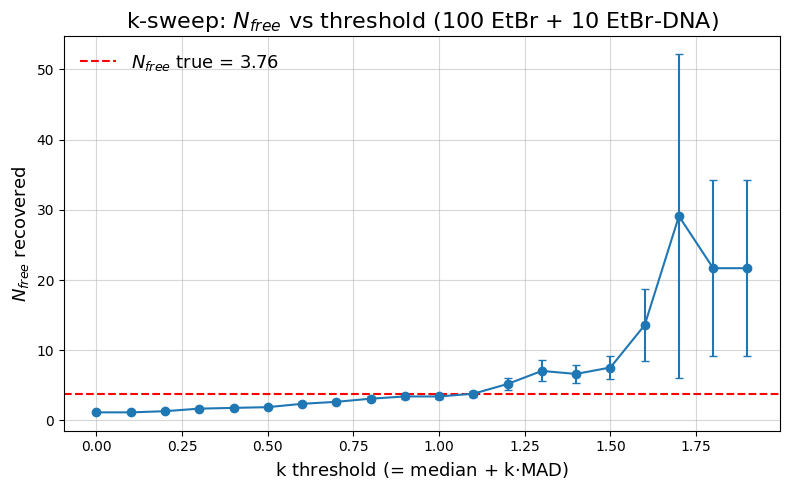

In [137]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    sweep_df_010.index,
    sweep_df_010['N_free'],
    yerr=sweep_df_010['N_free_err'],
    marker='o', capsize=3, linestyle='-', color='tab:blue'
)
ax.axhline(N_free_TRUE, color='red', linestyle='--', label=f'$N_{{free}}$ true = {N_free_TRUE:.2f}')
ax.set_xlabel('k threshold (= median + k$\\cdot$MAD)', fontsize=13)
ax.set_ylabel('$N_{free}$ recovered', fontsize=13)
ax.set_title('k-sweep: $N_{free}$ vs threshold (100 EtBr + 10 EtBr-DNA)', fontsize=16)
ax.legend(frameon=False, fontsize=13)
ax.grid(True, alpha=0.5)
plt.tight_layout()
plt.draw()
plt.savefig('./images/sweep_k_Nfree_etbr_dna_010.png')

**Observation.** The sweep shows a broad plateau around the true value ($3.76$) for $k \approx 0.8$–$1.2$, with the sweet spot at $k = 1.1$ (the code uses this value in the subsequent fit). For $k < 0.8$ the threshold is too low: bursts are only partially removed and $N_{free}$ stays below the true value; for $k > 1.5$ the removal becomes aggressive and $N_{free}$ drifts upwards with large error bars, as in the previous sections.

As $N_{bound}$ increases, the optimal $k$ decreases: with more blobs the bursts are more frequent and less extreme relative to the signal, so a lower threshold suffices.

#### Histogram of signal timestamps

In [138]:
bins_010 = np.arange(0, 120, 1e-2)
stats_010_sim = tk.trace_stats(ts_sig_010, bins=bins_010)

# Unburst with sweet-spot threshold
k_sweet = 1.1
thr_010 = median_010 + k_sweet * MAD_010
ts_010_unb = tk.unburst(ts_sig_010, bins=bins_010, threshold=thr_010)
print(f'Threshold (k={k_sweet}): {thr_010:.2f} cps')
print(f'Photons: total signal = {len(ts_sig_010)}, after unburst = {len(ts_010_unb)}')

Threshold (k=1.1): 22.79 cps
Photons: total signal = 293359, after unburst = 78722


/home/ciugam/Software/uv_envs/pyanalist/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


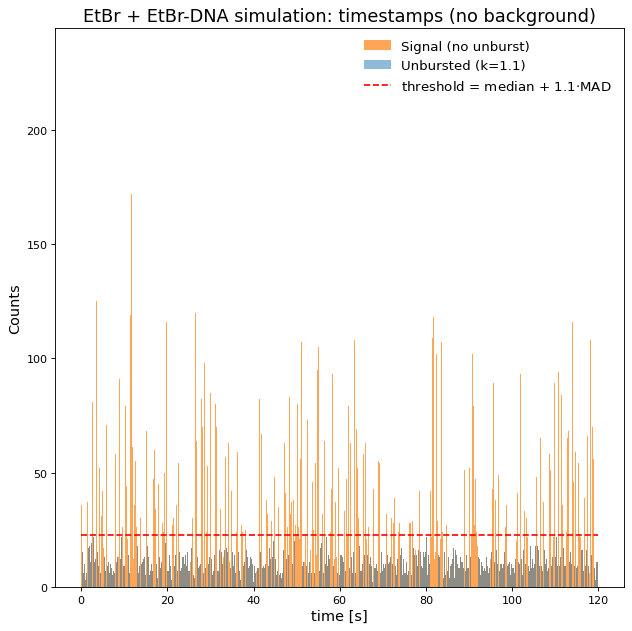

In [139]:
fig = plt.figure(figsize=(8,8), dpi=80)
ax = fig.add_subplot(1,1,1)
ax.set_title("EtBr + EtBr-DNA simulation: timestamps (no background)", fontsize=16)
ax.hist(ts_sig_010, bins=bins_010, color="tab:orange", lw=1, alpha=0.7, label='Signal (no unburst)')
ax.hist(ts_010_unb, bins=bins_010, color="tab:blue", lw=1, alpha=0.5, label=f'Unbursted (k={k_sweet})')
ax.hlines(thr_010, 0, 120, 'red', linestyle='--', label=f'threshold = median + {k_sweet}$\cdot$MAD')
ax.set_xlabel('time [s]', fontsize=13)
ax.set_ylabel('Counts', fontsize=13)
ax.legend(frameon=False, fontsize=12)
plt.tight_layout()
plt.draw()
plt.savefig('./images/hist_etbr_dna_010.png')

#### Estimate average count rates

In [140]:
F_signal_010 = ts_sig_010.size / ts_sig_010.max()
print(f"Signal count rate : {F_signal_010:.2f} cps")

Signal count rate : 2444.66 cps


#### Compute ACF and fit with 2-species diffusion model

The first population (free EtBr) has its $\tau_{diff}$ **fixed** to the value extracted from the free-EtBr analysis. Only $A_0$ of that species is fitted, together with $\tau_{diff}$ and $A_0$ of the second (bound) species.

In [141]:
# Ground-truth values from simulation parameters (effective PSF)
# Population 1: free EtBr
D_free_TRUE = params['particles']['D_etbr_free'] * (1e-6)**2
N_box_free  = params['particles']['n_etbr_free']
# Population 2: bound EtBr-DNA
D_bound_TRUE = params['particles']['D_etbr_dna'] * (1e-6)**2
N_box_bound  = params['particles']['n_etbr_dna_010']

# TRUE average molecules in effective confocal volume
N_free_TRUE  = N_box_free  * V_eff / V_box
N_bound_TRUE = N_box_bound * V_eff / V_box

# TRUE diffusion times
tau_d_free_TRUE  = W0_sm**2 / (4 * D_free_TRUE)
tau_d_bound_TRUE = W0_sm**2 / (4 * D_bound_TRUE)

print(f'GROUND TRUTH (2 species):')
print(f'  Free EtBr:      N={N_free_TRUE:.3f}, tau_diff={tau_d_free_TRUE*1e6:.1f} us, D={D_free_TRUE*1e12:.1f} um^2/s')
print(f'  Bound EtBr-DNA: N={N_bound_TRUE:.3f}, tau_diff={tau_d_bound_TRUE*1e6:.1f} us, D={D_bound_TRUE*1e12:.2f} um^2/s')

GROUND TRUTH (2 species):
  Free EtBr:      N=3.759, tau_diff=52.9 us, D=425.0 um^2/s
  Bound EtBr-DNA: N=0.376, tau_diff=45000.0 us, D=0.50 um^2/s


In [142]:
# Define tick unit for ACF time-lag and maximum time
unit_010 = 1e-6
T_010 = ts_sig_010.max()
T_010_unb = ts_010_unb.max()

# Compute ACF over data (both: raw signal and unbursted)
tau_010, G_010, Y_010 = tk.compute_G(ts_sig_010, ts_sig_010, unit_010, T_010, bins_per_dec=200)
tau_010_unb, G_010_unb, Y_010_unb = tk.compute_G(ts_010_unb, ts_010_unb, unit_010, T_010_unb, bins_per_dec=200)

# Fit range
tau_range_010 = (1e-6, 1e2)

# --- Fit parameters (shared) ---
# tau_1 (free EtBr) is FIXED to the value from the free-EtBr analysis
tau_1_fixed = tau_sm_fit

# Initial guesses: [tau_1, A0_1, tau_2, A0_2]
pars_010 = [tau_1_fixed, 0.3, tau_d_bound_TRUE, 0.1]
# Bounds: tau_1 tightly locked around the fixed value
bounds_010 = (
    [tau_1_fixed * 0.95, 1e-4, 1e-6, 1e-4],   # lower
    [tau_1_fixed * 1.05, 1e1,  1e-1,  1e1]     # upper
)

# --- Fit on raw signal (no unburst) ---
sigma_010 = 1.0 / np.sqrt(np.maximum(Y_010, 1))
popt_010, pcov_010, W0_fit_010, Z0_fit_010 = tk.fit_G(
    tau_010, G_010, pars_010, bounds_010,
    model="double",
    tau_range=tau_range_010, sigma=sigma_010, W0=W0_sm, Z0=Z0_sm
)

# --- Fit on unbursted data (k={k_sweet}) ---
sigma_010_unb = 1.0 / np.sqrt(np.maximum(Y_010_unb, 1))
popt_010_unb, pcov_010_unb, W0_fit_010_unb, Z0_fit_010_unb = tk.fit_G(
    tau_010_unb, G_010_unb, pars_010, bounds_010,
    model="double",
    tau_range=tau_range_010, sigma=sigma_010_unb, W0=W0_sm, Z0=Z0_sm
)

# Extract fit parameters and errors (raw signal)
tau_1_fit, A0_1_fit, tau_2_fit, A0_2_fit = popt_010
perr_010 = np.sqrt(np.diag(pcov_010))
tau_1_err, A0_1_err, tau_2_err, A0_2_err = perr_010

# Extract fit parameters and errors (unbursted)
tau_1_010_unb, A0_1_010_unb, tau_2_010_unb, A0_2_010_unb = popt_010_unb
perr_010_unb = np.sqrt(np.diag(pcov_010_unb))
tau_1_err_010_unb, A0_1_err_010_unb, tau_2_err_010_unb, A0_2_err_010_unb = perr_010_unb

# Diffusion coefficients (raw)
D_1_fit = W0_fit_010**2 / (4 * tau_1_fit)
D_2_fit = W0_fit_010**2 / (4 * tau_2_fit)
D_1_err = D_1_fit * tau_1_err / tau_1_fit
D_2_err = D_2_fit * tau_2_err / tau_2_fit

# Diffusion coefficients (unbursted)
D_1_010_unb = W0_fit_010_unb**2 / (4 * tau_1_010_unb)
D_2_010_unb = W0_fit_010_unb**2 / (4 * tau_2_010_unb)
D_1_err_010_unb = D_1_010_unb * tau_1_err_010_unb / tau_1_010_unb
D_2_err_010_unb = D_2_010_unb * tau_2_err_010_unb / tau_2_010_unb

#### Extract $N_{eff}$ from the 2-species fit

For each species: $N_{eff,i} = 1/A_{0,i}$

In [143]:
# N_eff for each species (raw signal)
N_1 = 1.0 / A0_1_fit
N_2 = 1.0 / A0_2_fit
N_1_err = N_1 * A0_1_err / A0_1_fit
N_2_err = N_2 * A0_2_err / A0_2_fit

# N_eff for each species (unbursted)
N_1_010_unb = 1.0 / A0_1_010_unb
N_2_010_unb = 1.0 / A0_2_010_unb
N_1_err_010_unb = N_1_010_unb * A0_1_err_010_unb / A0_1_010_unb
N_2_err_010_unb = N_2_010_unb * A0_2_err_010_unb / A0_2_010_unb

# Tabulate results
summary_010 = pd.DataFrame({
    'Simulation': ['019435 (raw)', f'019435 (unburst k={k_sweet})'],
    'tau_free [us]': [tau_1_fit*1e6, tau_1_010_unb*1e6],
    'tau_free_err [us]': [tau_1_err*1e6, tau_1_err_010_unb*1e6],
    'A0_free': [A0_1_fit, A0_1_010_unb],
    'N_free': [N_1, N_1_010_unb],
    'N_free_err': [N_1_err, N_1_err_010_unb],
    'A0_bound': [A0_2_fit, A0_2_010_unb],
    'A0_bound_err': [A0_2_err, A0_2_err_010_unb],
    'N_bound': [N_2, N_2_010_unb],
    'N_bound_err': [N_2_err, N_2_err_010_unb],
}).set_index('Simulation')

styled_010 = summary_010.style.format({
    'tau_free [us]': '{:.2f}', 'tau_free_err [us]': '{:.2f}',
    'A0_free': '{:.3g}', 'N_free': '{:.3g}', 'N_free_err': '{:.3g}',
    'A0_bound': '{:.3g}', 'A0_bound_err': '{:.3g}',
    'N_bound': '{:.3g}', 'N_bound_err': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '90px'), ('text-align', 'center')]}
])
display(styled_010)

# Expected values (ground truth)
expected_010 = pd.DataFrame({
    'Simulation': ['019435 (TRUE)'],
    'tau_free [us]': [tau_d_free_TRUE*1e6],
    'A0_free': [1.0 / N_free_TRUE],
    'N_free': [N_free_TRUE],
    'A0_bound': [1.0 / N_bound_TRUE],
    'N_bound': [N_bound_TRUE],
}).set_index('Simulation')
styled_exp_010 = expected_010.style.format({
    'tau_free [us]': '{:.1f}', 'A0_free': '{:.3g}', 'N_free': '{:.3g}',
    'A0_bound': '{:.3g}', 'N_bound': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '90px'), ('text-align', 'center')]}
])
display(styled_exp_010)

,tau_free [us],tau_free_err [us],A0_free,N_free,N_free_err,A0_bound,A0_bound_err,N_bound,N_bound_err
Simulation,,,,,,,,,
019435 (raw),45.68,6214.95,0.0001,1e+04,7.69e+05,1.33,0.000307,0.754,0.000175
019435 (unburst k=1.1),46.97,10.71,0.263,3.8,0.453,0.754,0.00228,1.33,0.00402


,tau_free [us],A0_free,N_free,A0_bound,N_bound
Simulation,,,,,
019435 (TRUE),52.9,0.266,3.76,2.66,0.376


**Observations.** Same pattern as the 8-blob case: the raw fit is fully degenerate ($N_{free} \approx 10^4$, $\delta N_{free} \sim 10^5$), while the unburst fit at $k = 1.1$ recovers $N_{free} = 3.8 \pm 0.45$, consistent with the ground truth ($3.76$) within ~0.1 $\sigma$. The residual slow component ($N_{bound} = 1.33$, true: $0.376$) again reflects surviving burst photons and is not quantitatively meaningful.

#### Plot ACF and fits

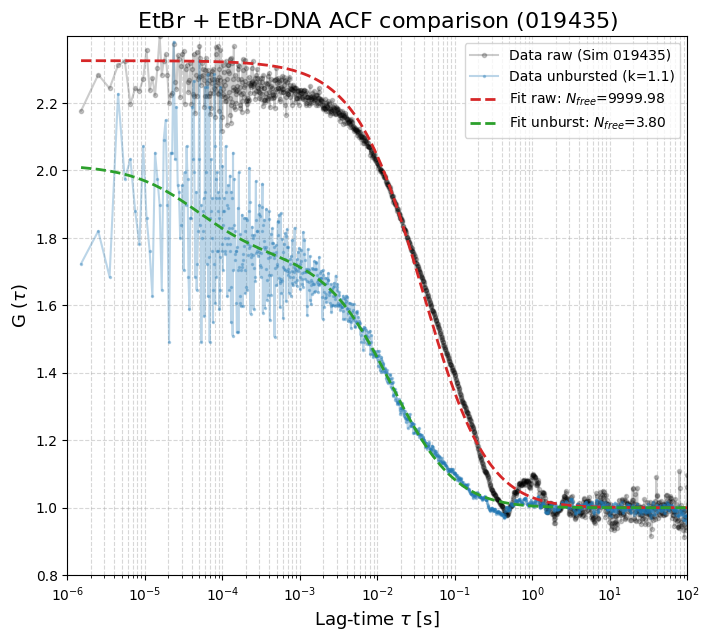

In [145]:
G_fit_010 = tk.diffusion_3d_double(tau_010, *popt_010)
G_fit_010_unb = tk.diffusion_3d_double(tau_010_unb, *popt_010_unb)

# Theoretical ACF with TRUE parameters
fig = plt.figure(figsize=(8,7), dpi=100)
ax = fig.add_subplot(1,1,1)
ax.set_title("EtBr + EtBr-DNA ACF comparison ($019435$)", fontsize=16)
ax.plot(
    tau_010, G_010, '.-', color='black', alpha=0.2,
    label='Data raw (Sim 019435)',
)
ax.plot(
    tau_010_unb, G_010_unb, '.-', color='tab:blue', alpha=0.3, ms=3,
    label=f'Data unbursted (k={k_sweet})',
)
ax.plot(
    tau_010, G_fit_010, '--', color='tab:red', lw=2,
    label=f'Fit raw: $N_{{free}}$={N_1:.2f}'
)
ax.plot(
    tau_010_unb, G_fit_010_unb, '--', color='tab:green', lw=2,
    label=f'Fit unburst: $N_{{free}}$={N_1_010_unb:.2f}'
)
ax.set_xlabel("Lag-time $\\tau$ [s]", fontsize=13)
ax.set_ylabel("G ($\\tau$)", fontsize=13)
ax.set_xlim(1e-6, 1e2)
ax.set_ylim(0.8, max(G_010.max(), G_010_unb.max()))
ax.set_xscale('log')
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend(frameon=True, fontsize=10)
plt.draw()
plt.savefig('./images/acf_etbr_dna_010.png')

**Note.** Same situation as 767a16: the raw ACF (grey) is lifted at short lags by the fast burst correlation, so the raw fit collapses to a single burst-dominated species ($N_{free} \to 10^4$, red curve). The unbursted ACF (blue) has a well-defined short-lag plateau and the free species becomes identifiable again ($N_{free} = 3.80$, green curve).

## EtBr + EtBr-DNA 12 blobs – Sim c1b4e2

In [146]:
# load simulated data (timestamps + particle IDs to separate signal/background)
ts_012_sim, par_012_sim = tk.load_sim_timestamps(
    path_simts, 'times_c1b4e2_P100_D4.2e-10_P12_D5e-13_11623pM_step1.0us_t_max120.0s_ID0-0.hdf5', return_par=True
)
# background photons carry particle ID >= num_particles + n_blobs (112); keep only signal
ts_sig_012 = ts_012_sim[par_012_sim < 112]
print(f'total photons: {len(ts_012_sim)} | signal: {len(ts_sig_012)} | background: {(par_012_sim >= 112).sum()}')

total photons: 356200 | signal: 323310 | background: 32890


#### Threshold sweep: $k \cdot MAD$ unburst vs $N_{free}$

Sweep $k$ over a range adapted to the blob density. At each step: unburst with $thr = median + k \cdot MAD$, compute ACF, fit 2-species model with $\tau_{free}$ fixed.

In [147]:
# Extract median and MAD from signal timestamps
bins_sweep = np.arange(0, 120, 1e-2)
stats_012 = tk.trace_stats(ts_sig_012, bins=bins_sweep)
median_012 = stats_012['median']
MAD_012 = stats_012['MAD']

# Ground-truth values (needed for the fit initial guess and expected N)
D_free_TRUE  = params['particles']['D_etbr_free'] * (1e-6)**2
D_bound_TRUE = params['particles']['D_etbr_dna'] * (1e-6)**2
N_box_free   = params['particles']['n_etbr_free']
N_box_bound  = params['particles']['n_etbr_dna_012']
N_free_TRUE  = N_box_free  * V_eff / V_box
N_bound_TRUE = N_box_bound * V_eff / V_box
tau_d_free_TRUE  = W0_sm**2 / (4 * D_free_TRUE)
tau_d_bound_TRUE = W0_sm**2 / (4 * D_bound_TRUE)

# Sweep parameters
ks = np.arange(0, 1.2, 0.05) 
unit_012 = 1e-6
tau_range_012 = (1e-6, 1e2)

# tau_free fixed from the free-EtBr fit done earlier in this notebook
tau_1_fixed = tau_sm_fit

tau_2_guess = W0_sm**2 / (4 * D_bound_TRUE)

# Store results
sweep_results = []
for k in ks:
    thr = median_012 + k * MAD_012
    ts_u = tk.unburst(ts_sig_012, bins=bins_sweep, threshold=thr)
    if len(ts_u) < 1000:
        sweep_results.append({
            'k': k, 'tau_free': np.nan, 'tau_free_err': np.nan,
            'A0_free': np.nan, 'N_free': np.nan, 'N_free_err': np.nan,
            'tau_bound': np.nan, 'tau_bound_err': np.nan,
            'A0_bound': np.nan, 'N_bound': np.nan, 'N_bound_err': np.nan
        })
        continue

    T_u = ts_u.max()
    tau_u, G_u, Y_u = tk.compute_G(ts_u, ts_u, unit_012, T_u, bins_per_dec=200)
    sigma_u = 1.0 / np.sqrt(np.maximum(Y_u, 1))

    # 2-species fit: [tau_1 (fixed), A0_1, tau_2, A0_2]
    pars_sweep = [tau_1_fixed, 0.3, tau_2_guess, 0.1]
    bounds_sweep = (
        [tau_1_fixed * 0.95, 1e-4, 1e-6, 1e-4],
        [tau_1_fixed * 1.05, 1e1,  1e-1,  1e1]
    )
    try:
        popt_u, pcov_u, _, _ = tk.fit_G(
            tau_u, G_u, pars_sweep, bounds_sweep,
            model="double",
            tau_range=tau_range_012, sigma=sigma_u, W0=W0_sm, Z0=Z0_sm
        )
        perr_u = np.sqrt(np.diag(pcov_u))
        t1, a1, t2, a2 = popt_u
        t1e, a1e, t2e, a2e = perr_u
        N1 = 1.0 / a1
        N2 = 1.0 / a2
        N1_err = N1 * a1e / a1
        N2_err = N2 * a2e / a2
    except Exception:
        sweep_results.append({
            'k': k, 'tau_free': np.nan, 'tau_free_err': np.nan,
            'A0_free': np.nan, 'N_free': np.nan, 'N_free_err': np.nan,
            'tau_bound': np.nan, 'tau_bound_err': np.nan,
            'A0_bound': np.nan, 'N_bound': np.nan, 'N_bound_err': np.nan
        })
        continue

    sweep_results.append({
        'k': k,
        'tau_free': t1, 'tau_free_err': t1e,
        'A0_free': a1, 'N_free': N1, 'N_free_err': N1_err,
        'tau_bound': t2, 'tau_bound_err': t2e,
        'A0_bound': a2, 'N_bound': N2, 'N_bound_err': N2_err
    })

# Convert to DataFrame
sweep_df_012 = pd.DataFrame(sweep_results).set_index('k')
display(sweep_df_012)

,tau_free,tau_free_err,A0_free,N_free,N_free_err,tau_bound,tau_bound_err,A0_bound,N_bound,N_bound_err
k,,,,,,,,,,
0.00,0.000046,0.000006,0.566038,1.766667,0.127438,0.025227,0.000072,1.431178,0.698725,0.001114
0.05,0.000046,0.000006,0.566038,1.766667,0.127438,0.025227,0.000072,1.431178,0.698725,0.001114
0.10,0.000046,0.000006,0.503394,1.986516,0.149937,0.023810,0.000071,1.298183,0.770307,0.001296
0.15,0.000046,0.000006,0.503394,1.986516,0.149937,0.023810,0.000071,1.298183,0.770307,0.001296
0.20,0.000046,0.000006,0.519775,1.923910,0.133836,0.023818,0.000072,1.205002,0.829874,0.001428
0.25,0.000046,0.000006,0.519775,1.923910,0.133836,0.023818,0.000072,1.205002,0.829874,0.001428
0.30,0.000046,0.000007,0.453738,2.203917,0.168855,0.021617,0.000069,1.144878,0.873456,0.001594
0.35,0.000046,0.000006,0.478718,2.088914,0.144736,0.022024,0.000071,1.073696,0.931362,0.001714
0.40,0.000046,0.000006,0.478718,2.088914,0.144736,0.022024,0.000071,1.073696,0.931362,0.001714


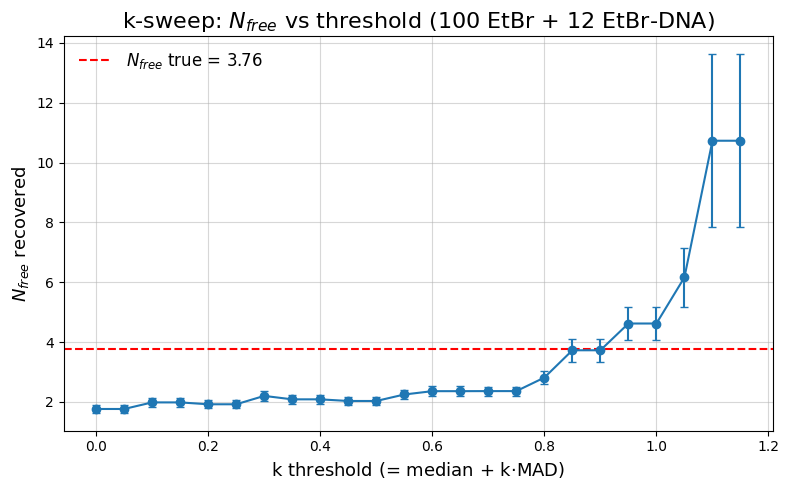

In [149]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    sweep_df_012.index,
    sweep_df_012['N_free'],
    yerr=sweep_df_012['N_free_err'],
    marker='o', capsize=3, linestyle='-', color='tab:blue'
)
ax.axhline(N_free_TRUE, color='red', linestyle='--', label=f'$N_{{free}}$ true = {N_free_TRUE:.2f}')
ax.set_xlabel('k threshold (= median + k$\\cdot$MAD)', fontsize=13)
ax.set_ylabel('$N_{free}$ recovered', fontsize=13)
ax.set_title('k-sweep: $N_{{free}}$ vs threshold (100 EtBr + 12 EtBr-DNA)', fontsize=16)
ax.legend(frameon=False, fontsize=12)
ax.grid(True, alpha=0.5)
plt.tight_layout()
plt.draw()
plt.savefig('./images/sweep_k_Nfree_etbr_dna_012.png')

**Observation.** The monotonic rise of $N_{free}$ with $k$ persists, but the good-cut region has narrowed: $N_{free}$ stays below the true value ($3.76$) up to $k \approx 0.8$, crosses it only in a narrow window $k \approx 0.85$–$0.95$, and then drifts upwards with large error bars for $k > 1$. The sweet spot is at $k = 0.85$. Compared to the 6- and 10-blob cases, where a broad plateau around the true value was visible, here the threshold must be chosen more carefully: with 12 blobs the burst contribution is strong enough that both under-removal ($k$ too low) and over-removal ($k$ too high) degrade the result within a narrow $k$ range.

The progressive trend in the sweet spot is clear: $k_{sweet}$ drops from 2.6 (6 blobs) to 0.85 (12 blobs), consistent with the $k_{sweet} \propto 1/N_{bound}$ scaling.

#### Histogram of signal timestamps

In [150]:
bins_012 = np.arange(0, 120, 1e-2)
stats_012_sim = tk.trace_stats(ts_sig_012, bins=bins_012)

# Unburst with sweet-spot threshold
k_sweet = 0.85
thr_012 = median_012 + k_sweet * MAD_012
ts_012_unb = tk.unburst(ts_sig_012, bins=bins_012, threshold=thr_012)
print(f'Threshold (k={k_sweet}): {thr_012:.2f} cps')
print(f'Photons: total signal = {len(ts_sig_012)}, after unburst = {len(ts_012_unb)}')

Threshold (k=0.85): 26.08 cps
Photons: total signal = 323310, after unburst = 86325


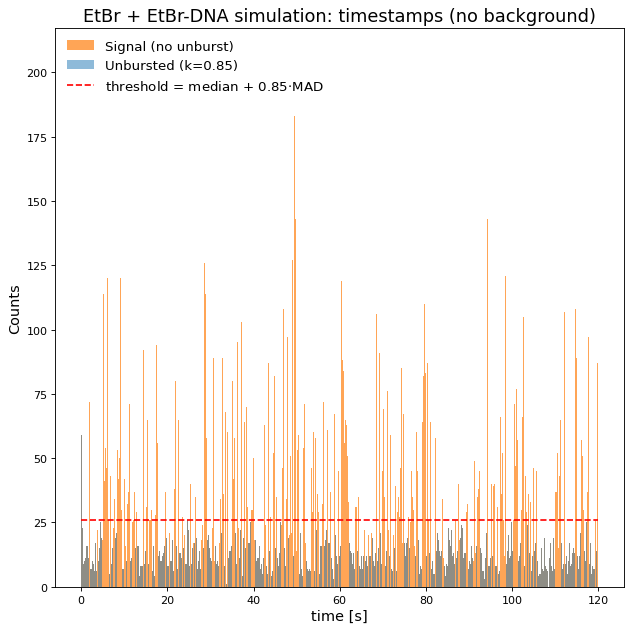

In [152]:
fig = plt.figure(figsize=(8,8), dpi=80)
ax = fig.add_subplot(1,1,1)
ax.set_title("EtBr + EtBr-DNA simulation: timestamps (no background)", fontsize=16)
ax.hist(ts_sig_012, bins=bins_012, color="tab:orange", lw=1, alpha=0.7, label='Signal (no unburst)')
ax.hist(ts_012_unb, bins=bins_012, color="tab:blue", lw=1, alpha=0.5, label=f'Unbursted (k={k_sweet})')
ax.hlines(thr_012, 0, 120, 'red', linestyle='--', label=f'threshold = median + {k_sweet}$\cdot$MAD')
ax.set_xlabel('time [s]', fontsize=13)
ax.set_ylabel('Counts', fontsize=13)
ax.legend(frameon=False, fontsize=12, loc='upper left')
plt.tight_layout()
plt.draw()
plt.savefig('./images/hist_etbr_dna_012.png')

#### Estimate average count rates

In [153]:
F_signal_012 = ts_sig_012.size / ts_sig_012.max()
print(f"Signal count rate : {F_signal_012:.2f} cps")

Signal count rate : 2694.27 cps


#### Compute ACF and fit with 2-species diffusion model

The first population (free EtBr) has its $\tau_{diff}$ **fixed** to the value extracted from the free-EtBr analysis. Only $A_0$ of that species is fitted, together with $\tau_{diff}$ and $A_0$ of the second (bound) species.

In [154]:
# Ground-truth values from simulation parameters (effective PSF)
# Population 1: free EtBr
D_free_TRUE = params['particles']['D_etbr_free'] * (1e-6)**2
N_box_free  = params['particles']['n_etbr_free']
# Population 2: bound EtBr-DNA
D_bound_TRUE = params['particles']['D_etbr_dna'] * (1e-6)**2
N_box_bound  = params['particles']['n_etbr_dna_012']

# TRUE average molecules in effective confocal volume
N_free_TRUE  = N_box_free  * V_eff / V_box
N_bound_TRUE = N_box_bound * V_eff / V_box

# TRUE diffusion times
tau_d_free_TRUE  = W0_sm**2 / (4 * D_free_TRUE)
tau_d_bound_TRUE = W0_sm**2 / (4 * D_bound_TRUE)

print(f'GROUND TRUTH (2 species):')
print(f'  Free EtBr:      N={N_free_TRUE:.3f}, tau_diff={tau_d_free_TRUE*1e6:.1f} us, D={D_free_TRUE*1e12:.1f} um^2/s')
print(f'  Bound EtBr-DNA: N={N_bound_TRUE:.3f}, tau_diff={tau_d_bound_TRUE*1e6:.1f} us, D={D_bound_TRUE*1e12:.2f} um^2/s')

GROUND TRUTH (2 species):
  Free EtBr:      N=3.759, tau_diff=52.9 us, D=425.0 um^2/s
  Bound EtBr-DNA: N=0.451, tau_diff=45000.0 us, D=0.50 um^2/s


In [155]:
# Define tick unit for ACF time-lag and maximum time
unit_012 = 1e-6
T_012 = ts_sig_012.max()
T_012_unb = ts_012_unb.max()

# Compute ACF over data (both: raw signal and unbursted)
tau_012, G_012, Y_012 = tk.compute_G(ts_sig_012, ts_sig_012, unit_012, T_012, bins_per_dec=200)
tau_012_unb, G_012_unb, Y_012_unb = tk.compute_G(ts_012_unb, ts_012_unb, unit_012, T_012_unb, bins_per_dec=200)

# Fit range
tau_range_012 = (1e-6, 1e2)

# --- Fit parameters (shared) ---
# tau_1 (free EtBr) is FIXED to the value from the free-EtBr analysis
tau_1_fixed = tau_sm_fit

# Initial guesses: [tau_1, A0_1, tau_2, A0_2]
pars_012 = [tau_1_fixed, 0.3, tau_d_bound_TRUE, 0.1]
# Bounds: tau_1 tightly locked around the fixed value
bounds_012 = (
    [tau_1_fixed * 0.95, 1e-4, 1e-6, 1e-4],   # lower
    [tau_1_fixed * 1.05, 1e1,  1e-1,  1e1]     # upper
)

# --- Fit on raw signal (no unburst) ---
sigma_012 = 1.0 / np.sqrt(np.maximum(Y_012, 1))
popt_012, pcov_012, W0_fit_012, Z0_fit_012 = tk.fit_G(
    tau_012, G_012, pars_012, bounds_012,
    model="double",
    tau_range=tau_range_012, sigma=sigma_012, W0=W0_sm, Z0=Z0_sm
)

# --- Fit on unbursted data (k={k_sweet}) ---
sigma_012_unb = 1.0 / np.sqrt(np.maximum(Y_012_unb, 1))
popt_012_unb, pcov_012_unb, W0_fit_012_unb, Z0_fit_012_unb = tk.fit_G(
    tau_012_unb, G_012_unb, pars_012, bounds_012,
    model="double",
    tau_range=tau_range_012, sigma=sigma_012_unb, W0=W0_sm, Z0=Z0_sm
)

# Extract fit parameters and errors (raw signal)
tau_1_fit, A0_1_fit, tau_2_fit, A0_2_fit = popt_012
perr_012 = np.sqrt(np.diag(pcov_012))
tau_1_err, A0_1_err, tau_2_err, A0_2_err = perr_012

# Extract fit parameters and errors (unbursted)
tau_1_012_unb, A0_1_012_unb, tau_2_012_unb, A0_2_012_unb = popt_012_unb
perr_012_unb = np.sqrt(np.diag(pcov_012_unb))
tau_1_err_012_unb, A0_1_err_012_unb, tau_2_err_012_unb, A0_2_err_012_unb = perr_012_unb

# Diffusion coefficients (raw)
D_1_fit = W0_fit_012**2 / (4 * tau_1_fit)
D_2_fit = W0_fit_012**2 / (4 * tau_2_fit)
D_1_err = D_1_fit * tau_1_err / tau_1_fit
D_2_err = D_2_fit * tau_2_err / tau_2_fit

# Diffusion coefficients (unbursted)
D_1_012_unb = W0_fit_012_unb**2 / (4 * tau_1_012_unb)
D_2_012_unb = W0_fit_012_unb**2 / (4 * tau_2_012_unb)
D_1_err_012_unb = D_1_012_unb * tau_1_err_012_unb / tau_1_012_unb
D_2_err_012_unb = D_2_012_unb * tau_2_err_012_unb / tau_2_012_unb

#### Extract $N_{eff}$ from the 2-species fit

For each species: $N_{eff,i} = 1/A_{0,i}$

In [156]:
# N_eff for each species (raw signal)
N_1 = 1.0 / A0_1_fit
N_2 = 1.0 / A0_2_fit
N_1_err = N_1 * A0_1_err / A0_1_fit
N_2_err = N_2 * A0_2_err / A0_2_fit

# N_eff for each species (unbursted)
N_1_012_unb = 1.0 / A0_1_012_unb
N_2_012_unb = 1.0 / A0_2_012_unb
N_1_err_012_unb = N_1_012_unb * A0_1_err_012_unb / A0_1_012_unb
N_2_err_012_unb = N_2_012_unb * A0_2_err_012_unb / A0_2_012_unb

# Tabulate results
summary_012 = pd.DataFrame({
    'Simulation': ['c1b4e2 (raw)', f'c1b4e2 (unburst k={k_sweet})'],
    'tau_free [us]': [tau_1_fit*1e6, tau_1_012_unb*1e6],
    'tau_free_err [us]': [tau_1_err*1e6, tau_1_err_012_unb*1e6],
    'A0_free': [A0_1_fit, A0_1_012_unb],
    'N_free': [N_1, N_1_012_unb],
    'N_free_err': [N_1_err, N_1_err_012_unb],
    'A0_bound': [A0_2_fit, A0_2_012_unb],
    'A0_bound_err': [A0_2_err, A0_2_err_012_unb],
    'N_bound': [N_2, N_2_012_unb],
    'N_bound_err': [N_2_err, N_2_err_012_unb],
}).set_index('Simulation')

styled_012 = summary_012.style.format({
    'tau_free [us]': '{:.2f}', 'tau_free_err [us]': '{:.2f}',
    'A0_free': '{:.3g}', 'N_free': '{:.3g}', 'N_free_err': '{:.3g}',
    'A0_bound': '{:.3g}', 'A0_bound_err': '{:.3g}',
    'N_bound': '{:.3g}', 'N_bound_err': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '90px'), ('text-align', 'center')]}
])
display(styled_012)

# Expected values (ground truth)
expected_012 = pd.DataFrame({
    'Simulation': ['c1b4e2 (TRUE)'],
    'tau_free [us]': [tau_d_free_TRUE*1e6],
    'A0_free': [1.0 / N_free_TRUE],
    'N_free': [N_free_TRUE],
    'A0_bound': [1.0 / N_bound_TRUE],
    'N_bound': [N_bound_TRUE],
}).set_index('Simulation')
styled_exp_012 = expected_012.style.format({
    'tau_free [us]': '{:.1f}', 'A0_free': '{:.3g}', 'N_free': '{:.3g}',
    'A0_bound': '{:.3g}', 'N_bound': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '90px'), ('text-align', 'center')]}
])
display(styled_exp_012)

,tau_free [us],tau_free_err [us],A0_free,N_free,N_free_err,A0_bound,A0_bound_err,N_bound,N_bound_err
Simulation,,,,,,,,,
c1b4e2 (raw),45.68,5899.78,0.0001,1e+04,7.33e+05,1.03,0.000273,0.97,0.000257
c1b4e2 (unburst k=0.85),45.68,9.00,0.268,3.73,0.379,0.914,0.0021,1.09,0.00251


,tau_free [us],A0_free,N_free,A0_bound,N_bound
Simulation,,,,,
c1b4e2 (TRUE),52.9,0.266,3.76,2.22,0.451


**Observations.** Same pattern: the raw fit is fully degenerate ($N_{free} \approx 10^4$, $\delta N_{free} \sim 7\times10^5$), while the unburst fit at $k = 0.85$ recovers $N_{free} = 3.73 \pm 0.38$, consistent with the ground truth ($3.76$) within ~0.1 $\sigma$. The residual slow component ($N_{bound} = 1.09$, true: $0.451$) again reflects surviving burst photons and is not quantitatively meaningful.

#### Plot ACF and fits

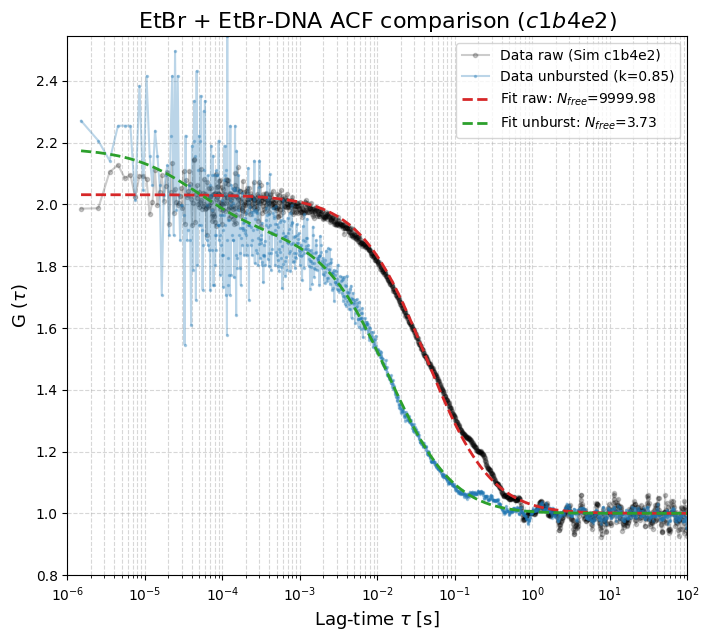

In [157]:
G_fit_012 = tk.diffusion_3d_double(tau_012, *popt_012)
G_fit_012_unb = tk.diffusion_3d_double(tau_012_unb, *popt_012_unb)

# Theoretical ACF with TRUE parameters
fig = plt.figure(figsize=(8,7), dpi=100)
ax = fig.add_subplot(1,1,1)
ax.set_title("EtBr + EtBr-DNA ACF comparison ($c1b4e2$)", fontsize=16)
ax.plot(
    tau_012, G_012, '.-', color='black', alpha=0.2,
    label='Data raw (Sim c1b4e2)',
)
ax.plot(
    tau_012_unb, G_012_unb, '.-', color='tab:blue', alpha=0.3, ms=3,
    label=f'Data unbursted (k={k_sweet})',
)
ax.plot(
    tau_012, G_fit_012, '--', color='tab:red', lw=2,
    label=f'Fit raw: $N_{{free}}$={N_1:.2f}'
)
ax.plot(
    tau_012_unb, G_fit_012_unb, '--', color='tab:green', lw=2,
    label=f'Fit unburst: $N_{{free}}$={N_1_012_unb:.2f}'
)
ax.set_xlabel("Lag-time $\\tau$ [s]", fontsize=13)
ax.set_ylabel("G ($\\tau$)", fontsize=13)
ax.set_xlim(1e-6, 1e2)
ax.set_ylim(0.8, max(G_012.max(), G_012_unb.max()))
ax.set_xscale('log')
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend(frameon=True, fontsize=10)
plt.draw()
plt.savefig('./images/acf_etbr_dna_012.png')

## EtBr + EtBr-DNA 15 blobs – Sim b8df77

Same workflow as the 6-blobs case, with 15 bound molecules.

In [158]:
# load simulated data (timestamps + particle IDs to separate signal/background)
ts_015_sim, par_015_sim = tk.load_sim_timestamps(
    path_simts, 'times_b8df77_P100_D4.2e-10_P15_D5e-13_11935pM_step1.0us_t_max120.0s_ID0-0.hdf5', return_par=True
)
# background photons carry particle ID >= num_particles + n_blobs (115); keep only signal
ts_sig_015 = ts_015_sim[par_015_sim < 115]
print(f'total photons: {len(ts_015_sim)} | signal: {len(ts_sig_015)} | background: {(par_015_sim >= 115).sum()}')

total photons: 386779 | signal: 353514 | background: 33265


#### Threshold sweep: $k \cdot MAD$ unburst vs $N_{free}$

Sweep $k$ over a range adapted to the blob density. At each step: unburst with $thr = median + k \cdot MAD$, compute ACF, fit 2-species model with $\tau_{free}$ fixed.

In [159]:
# Extract median and MAD from signal timestamps
bins_sweep = np.arange(0, 120, 1e-2)
stats_015 = tk.trace_stats(ts_sig_015, bins=bins_sweep)
median_015 = stats_015['median']
MAD_015 = stats_015['MAD']

# Ground-truth values (needed for the fit initial guess and expected N)
D_free_TRUE  = params['particles']['D_etbr_free'] * (1e-6)**2
D_bound_TRUE = params['particles']['D_etbr_dna'] * (1e-6)**2
N_box_free   = params['particles']['n_etbr_free']
N_box_bound  = params['particles']['n_etbr_dna_015']
N_free_TRUE  = N_box_free  * V_eff / V_box
N_bound_TRUE = N_box_bound * V_eff / V_box
tau_d_free_TRUE  = W0_sm**2 / (4 * D_free_TRUE)
tau_d_bound_TRUE = W0_sm**2 / (4 * D_bound_TRUE)

# Sweep parameters
ks = np.arange(0, 0.8, 0.05)
unit_015 = 1e-6
tau_range_015 = (1e-6, 1e2)

# tau_free fixed from the free-EtBr fit done earlier in this notebook
tau_1_fixed = tau_sm_fit

tau_2_guess = W0_sm**2 / (4 * D_bound_TRUE)

# Store results
sweep_results = []
for k in ks:
    thr = median_015 + k * MAD_015
    ts_u = tk.unburst(ts_sig_015, bins=bins_sweep, threshold=thr)
    if len(ts_u) < 1000:
        sweep_results.append({
            'k': k, 'tau_free': np.nan, 'tau_free_err': np.nan,
            'A0_free': np.nan, 'N_free': np.nan, 'N_free_err': np.nan,
            'tau_bound': np.nan, 'tau_bound_err': np.nan,
            'A0_bound': np.nan, 'N_bound': np.nan, 'N_bound_err': np.nan
        })
        continue

    T_u = ts_u.max()
    tau_u, G_u, Y_u = tk.compute_G(ts_u, ts_u, unit_015, T_u, bins_per_dec=200)
    sigma_u = 1.0 / np.sqrt(np.maximum(Y_u, 1))

    # 2-species fit: [tau_1 (fixed), A0_1, tau_2, A0_2]
    pars_sweep = [tau_1_fixed, 0.3, tau_2_guess, 0.1]
    bounds_sweep = (
        [tau_1_fixed * 0.95, 1e-4, 1e-6, 1e-4],
        [tau_1_fixed * 1.05, 1e1,  1e-1,  1e1]
    )
    try:
        popt_u, pcov_u, _, _ = tk.fit_G(
            tau_u, G_u, pars_sweep, bounds_sweep,
            model="double",
            tau_range=tau_range_015, sigma=sigma_u, W0=W0_sm, Z0=Z0_sm
        )
        perr_u = np.sqrt(np.diag(pcov_u))
        t1, a1, t2, a2 = popt_u
        t1e, a1e, t2e, a2e = perr_u
        N1 = 1.0 / a1
        N2 = 1.0 / a2
        N1_err = N1 * a1e / a1
        N2_err = N2 * a2e / a2
    except Exception:
        sweep_results.append({
            'k': k, 'tau_free': np.nan, 'tau_free_err': np.nan,
            'A0_free': np.nan, 'N_free': np.nan, 'N_free_err': np.nan,
            'tau_bound': np.nan, 'tau_bound_err': np.nan,
            'A0_bound': np.nan, 'N_bound': np.nan, 'N_bound_err': np.nan
        })
        continue

    sweep_results.append({
        'k': k,
        'tau_free': t1, 'tau_free_err': t1e,
        'A0_free': a1, 'N_free': N1, 'N_free_err': N1_err,
        'tau_bound': t2, 'tau_bound_err': t2e,
        'A0_bound': a2, 'N_bound': N2, 'N_bound_err': N2_err
    })

# Convert to DataFrame
sweep_df_015 = pd.DataFrame(sweep_results).set_index('k')
display(sweep_df_015)

,tau_free,tau_free_err,A0_free,N_free,N_free_err,tau_bound,tau_bound_err,A0_bound,N_bound,N_bound_err
k,,,,,,,,,,
0.00,0.000050,0.000003,1.265592,0.790144,0.022799,0.034473,0.000091,1.248380,0.801038,0.001172
0.05,0.000050,0.000003,1.265592,0.790144,0.022799,0.034473,0.000091,1.248380,0.801038,0.001172
0.10,0.000050,0.000004,0.848937,1.177944,0.047985,0.025623,0.000074,1.250900,0.799424,0.001296
0.15,0.000050,0.000004,0.811079,1.232925,0.049701,0.024619,0.000072,1.169573,0.855013,0.001430
0.20,0.000050,0.000004,0.811079,1.232925,0.049701,0.024619,0.000072,1.169573,0.855013,0.001430
0.25,0.000050,0.000004,0.718575,1.391643,0.060496,0.023286,0.000070,1.120986,0.892072,0.001530
0.30,0.000050,0.000005,0.611808,1.634499,0.080588,0.021096,0.000066,1.089971,0.917456,0.001649
0.35,0.000050,0.000005,0.542265,1.844117,0.099060,0.019687,0.000063,1.055752,0.947192,0.001757
0.40,0.000050,0.000005,0.542265,1.844117,0.099060,0.019687,0.000063,1.055752,0.947192,0.001757


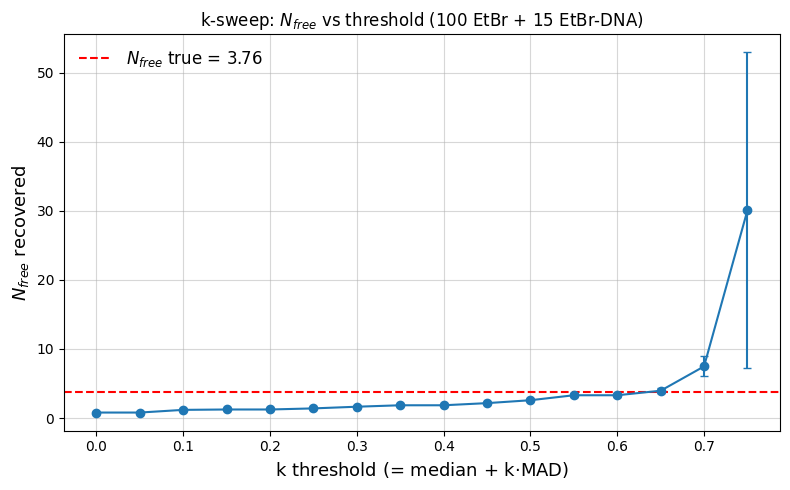

In [162]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    sweep_df_015.index,
    sweep_df_015['N_free'],
    yerr=sweep_df_015['N_free_err'],
    marker='o', capsize=3, linestyle='-', color='tab:blue'
)
ax.axhline(N_free_TRUE, color='red', linestyle='--', label=f'$N_{{free}}$ true = {N_free_TRUE:.2f}')
ax.set_xlabel('k threshold (= median + k$\\cdot$MAD)', fontsize=13)
ax.set_ylabel('$N_{free}$ recovered', fontsize=13)
ax.set_title('k-sweep: $N_{free}$ vs threshold (100 EtBr + 15 EtBr-DNA)')
ax.legend(frameon=False, fontsize=12)
ax.grid(True, alpha=0.5)
plt.tight_layout()
plt.draw()
plt.savefig('./images/sweep_k_Nfree_etbr_dna_015.png')

**Observation.** Sweet spot at $k = 0.65$. Even the fit at $k=0$ gives a finite (though incorrect) $N_{free} \approx 0.79$, because with 15 blobs the burst signal is so dominant that the 2-species model can partially resolve both components without aggressive preprocessing.

#### Histogram of signal timestamps

In [163]:
bins_015 = np.arange(0, 120, 1e-2)
stats_015_sim = tk.trace_stats(ts_sig_015, bins=bins_015)

# Unburst with sweet-spot threshold
k_sweet = 0.65
thr_015 = median_015 + k_sweet * MAD_015
ts_015_unb = tk.unburst(ts_sig_015, bins=bins_015, threshold=thr_015)
print(f'Threshold (k={k_sweet}): {thr_015:.2f} cps')
print(f'Photons: total signal = {len(ts_sig_015)}, after unburst = {len(ts_015_unb)}')

Threshold (k=0.65): 27.64 cps
Photons: total signal = 353514, after unburst = 87283


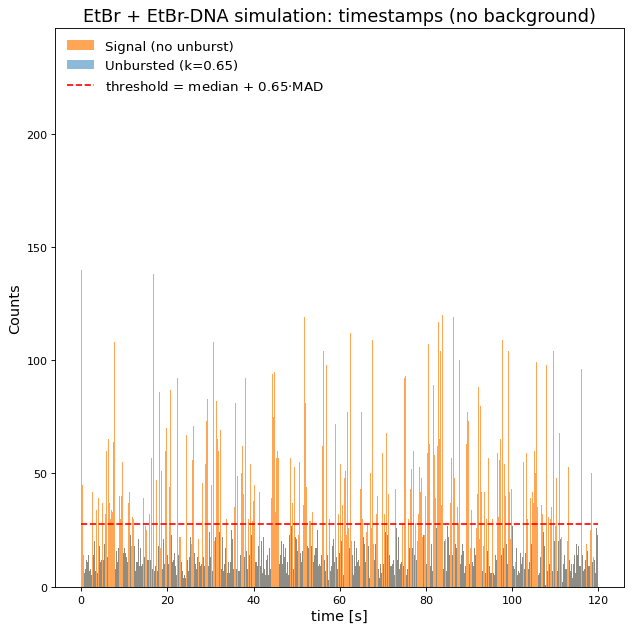

In [164]:
fig = plt.figure(figsize=(8,8), dpi=80)
ax = fig.add_subplot(1,1,1)
ax.set_title("EtBr + EtBr-DNA simulation: timestamps (no background)", fontsize=16)
ax.hist(ts_sig_015, bins=bins_015, color="tab:orange", lw=1, alpha=0.7, label='Signal (no unburst)')
ax.hist(ts_015_unb, bins=bins_015, color="tab:blue", lw=1, alpha=0.5, label=f'Unbursted (k={k_sweet})')
ax.hlines(thr_015, 0, 120, 'red', linestyle='--', label=f'threshold = median + {k_sweet}$\cdot$MAD')
ax.set_xlabel('time [s]', fontsize=13)
ax.set_ylabel('Counts', fontsize=13)
ax.legend(loc='upper left', frameon=False, fontsize=12)
plt.tight_layout()
plt.draw()
plt.savefig('./images/hist_etbr_dna_015.png')

#### Estimate average count rates

In [165]:
F_signal_015 = ts_sig_015.size / ts_sig_015.max()
print(f"Signal count rate : {F_signal_015:.2f} cps")

Signal count rate : 2945.96 cps


#### Compute ACF and fit with 2-species diffusion model

The first population (free EtBr) has its $\tau_{diff}$ **fixed** to the value extracted from the free-EtBr analysis. Only $A_0$ of that species is fitted, together with $\tau_{diff}$ and $A_0$ of the second (bound) species.

In [166]:
# Ground-truth values from simulation parameters (effective PSF)
# Population 1: free EtBr
D_free_TRUE = params['particles']['D_etbr_free'] * (1e-6)**2
N_box_free  = params['particles']['n_etbr_free']
# Population 2: bound EtBr-DNA
D_bound_TRUE = params['particles']['D_etbr_dna'] * (1e-6)**2
N_box_bound  = params['particles']['n_etbr_dna_015']

# TRUE average molecules in effective confocal volume
N_free_TRUE  = N_box_free  * V_eff / V_box
N_bound_TRUE = N_box_bound * V_eff / V_box

# TRUE diffusion times
tau_d_free_TRUE  = W0_sm**2 / (4 * D_free_TRUE)
tau_d_bound_TRUE = W0_sm**2 / (4 * D_bound_TRUE)

print(f'GROUND TRUTH (2 species):')
print(f'  Free EtBr:      N={N_free_TRUE:.3f}, tau_diff={tau_d_free_TRUE*1e6:.1f} us, D={D_free_TRUE*1e12:.1f} um^2/s')
print(f'  Bound EtBr-DNA: N={N_bound_TRUE:.3f}, tau_diff={tau_d_bound_TRUE*1e6:.1f} us, D={D_bound_TRUE*1e12:.2f} um^2/s')

GROUND TRUTH (2 species):
  Free EtBr:      N=3.759, tau_diff=52.9 us, D=425.0 um^2/s
  Bound EtBr-DNA: N=0.564, tau_diff=45000.0 us, D=0.50 um^2/s


In [167]:
# Define tick unit for ACF time-lag and maximum time
unit_015 = 1e-6
T_015 = ts_sig_015.max()
T_015_unb = ts_015_unb.max()

# Compute ACF over data (both: raw signal and unbursted)
tau_015, G_015, Y_015 = tk.compute_G(ts_sig_015, ts_sig_015, unit_015, T_015, bins_per_dec=200)
tau_015_unb, G_015_unb, Y_015_unb = tk.compute_G(ts_015_unb, ts_015_unb, unit_015, T_015_unb, bins_per_dec=200)

# Fit range
tau_range_015 = (1e-6, 1e2)

# --- Fit parameters (shared) ---
# tau_1 (free EtBr) is FIXED to the value from the free-EtBr analysis
tau_1_fixed = tau_sm_fit

# Initial guesses: [tau_1, A0_1, tau_2, A0_2]
pars_015 = [tau_1_fixed, 0.3, tau_d_bound_TRUE, 0.1]
# Bounds: tau_1 tightly locked around the fixed value
bounds_015 = (
    [tau_1_fixed * 0.95, 1e-4, 1e-6, 1e-4],   # lower
    [tau_1_fixed * 1.05, 1e1,  1e-1,  1e1]     # upper
)

# --- Fit on raw signal (no unburst) ---
sigma_015 = 1.0 / np.sqrt(np.maximum(Y_015, 1))
popt_015, pcov_015, W0_fit_015, Z0_fit_015 = tk.fit_G(
    tau_015, G_015, pars_015, bounds_015,
    model="double",
    tau_range=tau_range_015, sigma=sigma_015, W0=W0_sm, Z0=Z0_sm
)

# --- Fit on unbursted data (k={k_sweet}) ---
sigma_015_unb = 1.0 / np.sqrt(np.maximum(Y_015_unb, 1))
popt_015_unb, pcov_015_unb, W0_fit_015_unb, Z0_fit_015_unb = tk.fit_G(
    tau_015_unb, G_015_unb, pars_015, bounds_015,
    model="double",
    tau_range=tau_range_015, sigma=sigma_015_unb, W0=W0_sm, Z0=Z0_sm
)

# Extract fit parameters and errors (raw signal)
tau_1_fit, A0_1_fit, tau_2_fit, A0_2_fit = popt_015
perr_015 = np.sqrt(np.diag(pcov_015))
tau_1_err, A0_1_err, tau_2_err, A0_2_err = perr_015

# Extract fit parameters and errors (unbursted)
tau_1_015_unb, A0_1_015_unb, tau_2_015_unb, A0_2_015_unb = popt_015_unb
perr_015_unb = np.sqrt(np.diag(pcov_015_unb))
tau_1_err_015_unb, A0_1_err_015_unb, tau_2_err_015_unb, A0_2_err_015_unb = perr_015_unb

# Diffusion coefficients (raw)
D_1_fit = W0_fit_015**2 / (4 * tau_1_fit)
D_2_fit = W0_fit_015**2 / (4 * tau_2_fit)
D_1_err = D_1_fit * tau_1_err / tau_1_fit
D_2_err = D_2_fit * tau_2_err / tau_2_fit

# Diffusion coefficients (unbursted)
D_1_015_unb = W0_fit_015_unb**2 / (4 * tau_1_015_unb)
D_2_015_unb = W0_fit_015_unb**2 / (4 * tau_2_015_unb)
D_1_err_015_unb = D_1_015_unb * tau_1_err_015_unb / tau_1_015_unb
D_2_err_015_unb = D_2_015_unb * tau_2_err_015_unb / tau_2_015_unb

#### Extract $N_{eff}$ from the 2-species fit

For each species: $N_{eff,i} = 1/A_{0,i}$

In [168]:
# N_eff for each species (raw signal)
N_1 = 1.0 / A0_1_fit
N_2 = 1.0 / A0_2_fit
N_1_err = N_1 * A0_1_err / A0_1_fit
N_2_err = N_2 * A0_2_err / A0_2_fit

# N_eff for each species (unbursted)
N_1_015_unb = 1.0 / A0_1_015_unb
N_2_015_unb = 1.0 / A0_2_015_unb
N_1_err_015_unb = N_1_015_unb * A0_1_err_015_unb / A0_1_015_unb
N_2_err_015_unb = N_2_015_unb * A0_2_err_015_unb / A0_2_015_unb

# Tabulate results
summary_015 = pd.DataFrame({
    'Simulation': ['b8df77 (raw)', f'b8df77 (unburst k={k_sweet})'],
    'tau_free [us]': [tau_1_fit*1e6, tau_1_015_unb*1e6],
    'tau_free_err [us]': [tau_1_err*1e6, tau_1_err_015_unb*1e6],
    'A0_free': [A0_1_fit, A0_1_015_unb],
    'N_free': [N_1, N_1_015_unb],
    'N_free_err': [N_1_err, N_1_err_015_unb],
    'A0_bound': [A0_2_fit, A0_2_015_unb],
    'A0_bound_err': [A0_2_err, A0_2_err_015_unb],
    'N_bound': [N_2, N_2_015_unb],
    'N_bound_err': [N_2_err, N_2_err_015_unb],
}).set_index('Simulation')

styled_015 = summary_015.style.format({
    'tau_free [us]': '{:.2f}', 'tau_free_err [us]': '{:.2f}',
    'A0_free': '{:.3g}', 'N_free': '{:.3g}', 'N_free_err': '{:.3g}',
    'A0_bound': '{:.3g}', 'A0_bound_err': '{:.3g}',
    'N_bound': '{:.3g}', 'N_bound_err': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '90px'), ('text-align', 'center')]}
])
display(styled_015)

# Expected values (ground truth)
expected_015 = pd.DataFrame({
    'Simulation': ['b8df77 (TRUE)'],
    'tau_free [us]': [tau_d_free_TRUE*1e6],
    'A0_free': [1.0 / N_free_TRUE],
    'N_free': [N_free_TRUE],
    'A0_bound': [1.0 / N_bound_TRUE],
    'N_bound': [N_bound_TRUE],
}).set_index('Simulation')
styled_exp_015 = expected_015.style.format({
    'tau_free [us]': '{:.1f}', 'A0_free': '{:.3g}', 'N_free': '{:.3g}',
    'A0_bound': '{:.3g}', 'N_bound': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '90px'), ('text-align', 'center')]}
])
display(styled_exp_015)

,tau_free [us],tau_free_err [us],A0_free,N_free,N_free_err,A0_bound,A0_bound_err,N_bound,N_bound_err
Simulation,,,,,,,,,
b8df77 (raw),45.68,5534.92,0.0001,1e+04,6.83e+05,0.994,0.000281,1.01,0.000284
b8df77 (unburst k=0.65),50.49,9.89,0.253,3.95,0.397,0.99,0.00208,1.01,0.00212


,tau_free [us],A0_free,N_free,A0_bound,N_bound
Simulation,,,,,
b8df77 (TRUE),52.9,0.266,3.76,1.77,0.564


**Observations.** Same pattern as the previous sections: the raw fit is fully degenerate ($N_{free} \approx 10^4$, $\delta N_{free} \sim 7\times10^5$), while the unburst fit at $k = 0.65$ recovers $N_{free} = 3.95 \pm 0.40$, consistent with the ground truth ($3.76$) within ~0.5 $\sigma$. The residual slow component ($N_{bound} = 1.01$, true: $0.564$) again reflects surviving burst photons and is not quantitatively meaningful. Note that this is the most demanding case of the series: with 15 bound blobs the burst contribution is strongest, the sweet spot sits at the lowest $k$ ($0.65$), and the good-cut window in the sweep is the narrowest.

#### Plot ACF and fits

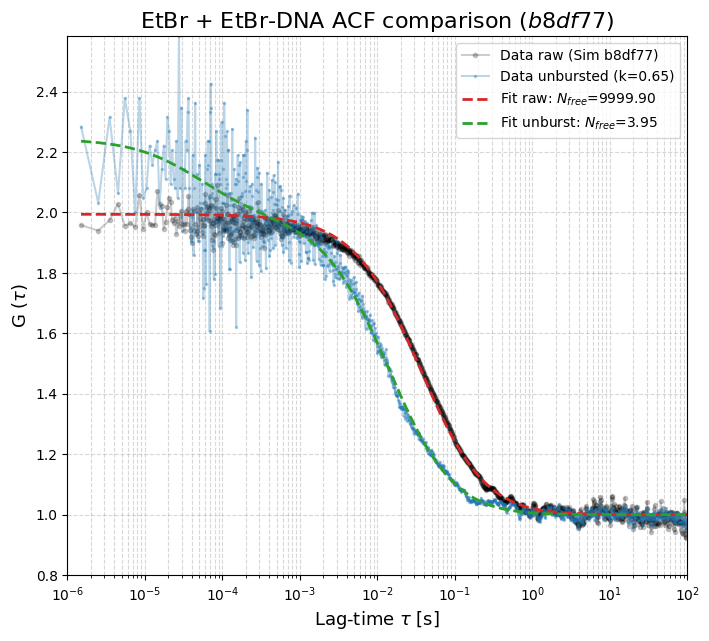

In [169]:
G_fit_015 = tk.diffusion_3d_double(tau_015, *popt_015)
G_fit_015_unb = tk.diffusion_3d_double(tau_015_unb, *popt_015_unb)

# Theoretical ACF with TRUE parameters
fig = plt.figure(figsize=(8,7), dpi=100)
ax = fig.add_subplot(1,1,1)
ax.set_title("EtBr + EtBr-DNA ACF comparison ($b8df77$)", fontsize=16)
ax.plot(
    tau_015, G_015, '.-', color='black', alpha=0.2,
    label='Data raw (Sim b8df77)',
)
ax.plot(
    tau_015_unb, G_015_unb, '.-', color='tab:blue', alpha=0.3, ms=3,
    label=f'Data unbursted (k={k_sweet})',
)
ax.plot(
    tau_015, G_fit_015, '--', color='tab:red', lw=2,
    label=f'Fit raw: $N_{{free}}$={N_1:.2f}'
)
ax.plot(
    tau_015_unb, G_fit_015_unb, '--', color='tab:green', lw=2,
    label=f'Fit unburst: $N_{{free}}$={N_1_015_unb:.2f}'
)
ax.set_xlabel("Lag-time $\\tau$ [s]", fontsize=13)
ax.set_ylabel("G ($\\tau$)", fontsize=13)
ax.set_xlim(1e-6, 1e2)
ax.set_ylim(0.8, max(G_015.max(), G_015_unb.max()))
ax.set_xscale('log')
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend(frameon=True, fontsize=10)
plt.draw()
plt.savefig('./images/acf_etbr_dna_015.png')

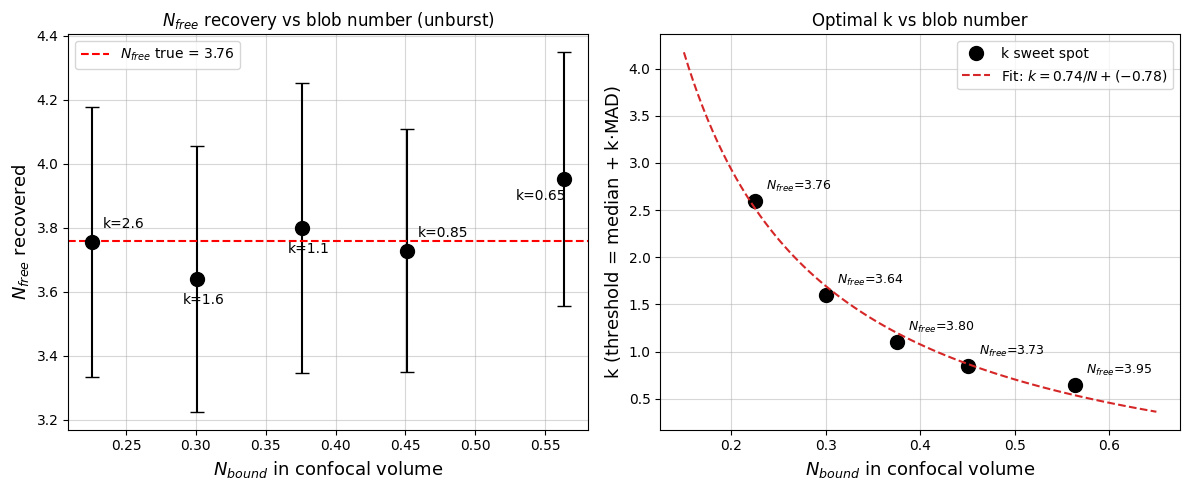

In [170]:
# Summary: N_free recovered and k_sweet vs number of blobs in confocal volume
n_blobs_box = [6, 8, 10, 12, 15]
N_bound_eff = np.array([n * V_eff / V_box for n in n_blobs_box])

N_free_vals = [N_1_006_unb, N_1_008_unb, N_1_010_unb, N_1_012_unb, N_1_015_unb]
N_free_errs = [N_1_err_006_unb, N_1_err_008_unb, N_1_err_010_unb, N_1_err_012_unb, N_1_err_015_unb]
k_sweets    = np.array([2.6, 1.6, 1.1, 0.85, 0.65])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# --- Left panel: N_free vs N_bound_eff ---
ax1.errorbar(N_bound_eff, N_free_vals, yerr=N_free_errs,
             marker='o', markersize=10, capsize=5, linestyle='None',
             color='black', ecolor='black')
ax1.axhline(N_free_TRUE, color='red', linestyle='--',
            label=f'$N_{{free}}$ true = {N_free_TRUE:.2f}')
for i_pt, (x, y, k) in enumerate(zip(N_bound_eff, N_free_vals, k_sweets)):
    if i_pt in (1, 2):  # second and third: annotate below
        offset = (-10, -18)
    elif i_pt == len(k_sweets) - 1:  # rightmost: annotate lower-left
        offset = (-35, -15)
    else:               # others: upper-right
        offset = (8, 10)
    ax1.annotate(f'k={k}', (x, y), textcoords='offset points',
                 xytext=offset, fontsize=10, color='black')
ax1.set_xlabel('$N_{bound}$ in confocal volume', fontsize=13)
ax1.set_ylabel('$N_{free}$ recovered', fontsize=13)
ax1.set_title('$N_{free}$ recovery vs blob number (unburst)')
ax1.legend(frameon=True)
ax1.grid(True, alpha=0.5)

# --- Right panel: k_sweet vs N_bound_eff with hyperbolic fit ---
ax2.plot(N_bound_eff, k_sweets, 'o', color='black', markersize=10, label='k sweet spot')
for x, y, nf in zip(N_bound_eff, k_sweets, N_free_vals):
    ax2.annotate(f'$N_{{free}}$={nf:.2f}', (x, y), textcoords='offset points',
                 xytext=(8, 8), fontsize=9, color='black')

popt_k, pcov_k = tk.fit_k_sweep(N_bound_eff, k_sweets)
a_fit, b_fit = popt_k
N_fine = np.linspace(0.15, 0.65, 100)
ax2.plot(N_fine, a_fit / N_fine + b_fit, '--', color='tab:red',
         label=f'Fit: $k = {a_fit:.2f}/N + ({b_fit:.2f})$')

ax2.set_xlabel('$N_{bound}$ in confocal volume', fontsize=13)
ax2.set_ylabel('k (threshold = median + k$\cdot$MAD)', fontsize=13)
ax2.set_title('Optimal k vs blob number')
ax2.legend(frameon=True)
ax2.grid(True, alpha=0.5)

plt.tight_layout()
plt.draw()
plt.savefig('./images/Nfree_vs_blobs.png')

**Summary.** Across all five blob densities the unburst preprocess recovers $N_{free}$ consistently: every point in the left panel is compatible with the ground truth ($3.76$) within its (1 $\sigma$) error bar, despite the increasing burst load. The right panel shows that the optimal threshold follows a hyperbolic law, fitted as

$$k_{sweet} = \frac{0.74}{N_{bound}} - 0.78$$

i.e. $k_{sweet}$ decreases roughly as $1/N_{bound}$: the more bound molecules in the confocal volume, the more frequent (and less extreme) the bursts become, and the lower the threshold needed to isolate them. This scaling provides a practical, data-driven rule for choosing the unburst threshold when the number of bound species is unknown a priori: one can estimate it from the histogram statistics (median, MAD) and the observed burst frequency, or calibrate it on a reference sample.

---

## Conclusions

**What was expected.**
- The 3D diffusion model should recover $\tau_{diff}$ and $N_{eff}$ for a single species.
- Burst events from DNA complexes should distort the ACF of the mixed sample, making the free-species amplitude unrecoverable without preprocessing.
- A threshold-based removal ($median + k \cdot MAD$) should isolate and remove bursts, restoring correct $N_{free}$ recovery.

**What worked.**
- Free EtBr: $\tau_{diff} = 48.1 \pm 9.4\,\mu s$ (true: 52.9 $\mu s$), $N_{eff} = 3.63$ (true: 3.76). Background dilutes $A_0$ but does not bias $\tau_{diff}$.
- Unburst + 2-species fit: $N_{free}$ is correctly recovered for all 5 blob densities (6, 8, 10, 12, 15) when the appropriate $k$ is used.
- The optimal $k$ follows a hyperbolic decay: $k \approx a/N_{bound}^{eff} + b$, enabling prediction of the sweet spot for new samples without a full sweep.

**What did not work / limitations.**
- The raw 2-species fit (no unburst) fails as the blob number grows: at 6 blobs it returns a finite but strongly biased $N_{free} \approx 45$, while for 8, 10, 12, 15 blobs it is fully degenerate ($N_{free} \to 10^4$ with meaningless error bars), because the burst-dominated ACF is incompatible with any finite free-species amplitude.
- The method relies on a **clear separation** between signal and burst populations in the histogram. This condition is met in noise-free simulations but may not hold for real data with high background (see `3b_realdata_analysis.ipynb`).

**Possible improvements.**
- Extend to $>2$ species (e.g., multiple DNA lengths) with a multi-exponential model.
- Replace the fixed-threshold unburst with an adaptive, per-frame threshold if the burst statistics are non-stationary.
- Validate on real data with low background (e.g., spectrally gated detection) to confirm transferability.